# Citi Bike project, part 2: analysis

Group 01: William Challma, Thomas Savazzi, Alessandro Simone

Which stations will run out of bikes tomorrow morning, and should the trucks go first to commuter or to leisure stations?

We worked in VS Code with the csv files in the same folder as this notebook, so the files are read only by their name. They come from the cleaning notebook in `1_Data_cleaning`:

| File | One row is | Used for |
|---|---|---|
| `station_day.csv` | one station on one day (851,613 rows) | first look, demand regression, empty-station prediction, stress test |
| `stations.csv` | one station, with its 24-hour profiles (2,318 rows) | PCA and k-means |
| `trips_sample.csv` | one ride, 0.4% stratified sample (202,423 rows) | members vs casual riders |
| `reviews_clean.csv` | one App Store review (500 rows) | topic model (LDA) |

The other csv files (cleaning logs, weather, sample check) are only used for the tables of the report. The whole notebook runs in about 5 minutes.

In [ ]:
# For google colab
# !pip install gensim mlxtend
# from google.colab import drive
# drive.mount('/content/drive')
# import os
# os.chdir('/content/drive/MyDrive/Citi Bike/2_Analysis')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso, Ridge
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn import metrics
from sklearn.metrics import mean_squared_error, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import xgboost as xgb

import warnings
warnings.filterwarnings('ignore')

In [3]:
stations = pd.read_csv('stations.csv')
station_day = pd.read_csv('station_day.csv', parse_dates=['date'])
trips = pd.read_csv('trips_sample.csv', parse_dates=['started_at', 'date'])
reviews = pd.read_csv('reviews_clean.csv')

print(stations.shape, station_day.shape, trips.shape, reviews.shape)

(2318, 106) (851613, 25) (202423, 19) (500, 6)


In [4]:
station_day.head()

,station_name,date,capacity,polls,pct_empty_day,pct_full_day,pct_empty_evening,pct_empty_morning,pct_full_evening,pct_full_morning,...,arr_morning,arr_other,arrivals,tavg,prcp,wspd,weekday,month,is_weekend,holiday
0,1 Ave & E 110 St,2025-08-01,25.0,720,0.0,14.03,0.0,0.0,15.83,0.0,...,14.0,46.0,101.0,21.3,1.0,15.8,4,8,False,False
1,1 Ave & E 110 St,2025-08-02,25.0,720,0.0,11.25,0.0,0.0,0.00,0.0,...,11.0,67.0,110.0,23.4,0.0,7.8,5,8,True,False
2,1 Ave & E 110 St,2025-08-03,25.0,720,0.0,5.42,0.0,0.0,0.00,0.0,...,10.0,58.0,87.0,24.8,0.0,8.4,6,8,True,False
3,1 Ave & E 110 St,2025-08-04,25.0,720,0.0,0.56,0.0,0.0,0.00,0.0,...,16.0,45.0,98.0,25.8,0.0,7.4,0,8,False,False
4,1 Ave & E 110 St,2025-08-05,25.0,720,0.0,5.97,0.0,0.0,3.33,0.0,...,21.0,56.0,110.0,25.4,0.0,8.0,1,8,False,False


# 1. First look at the data

## 1.1 When are stations empty or full?

Average over all stations of the share of time with no bike (empty) or no free dock (full), for each hour of a weekday.

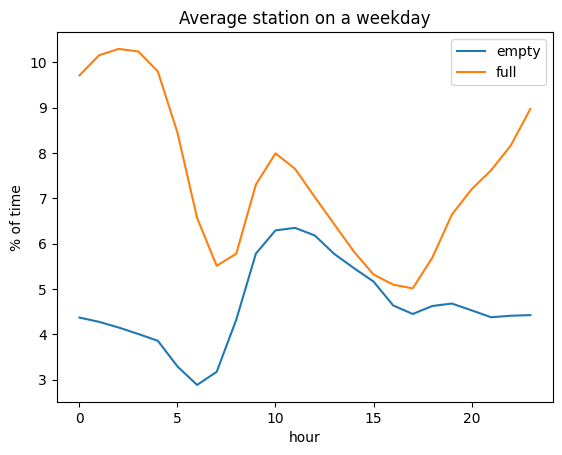

empty at 6am: 2.9  empty at 11am: 6.3


In [5]:
empty_by_hour = stations[['empty_' + str(h) for h in range(24)]].mean().values
full_by_hour = stations[['full_' + str(h) for h in range(24)]].mean().values

plt.plot(range(24), empty_by_hour, label='empty')
plt.plot(range(24), full_by_hour, label='full')
plt.xlabel('hour')
plt.ylabel('% of time')
plt.legend()
plt.title('Average station on a weekday')
plt.show()

print('empty at 6am:', empty_by_hour[6].round(1), ' empty at 11am:', empty_by_hour[11].round(1))

The share of time a station is empty more than doubles between 6am (2.9%) and 11am (6.3%), when people have ridden to work.

## 1.2 Seasons

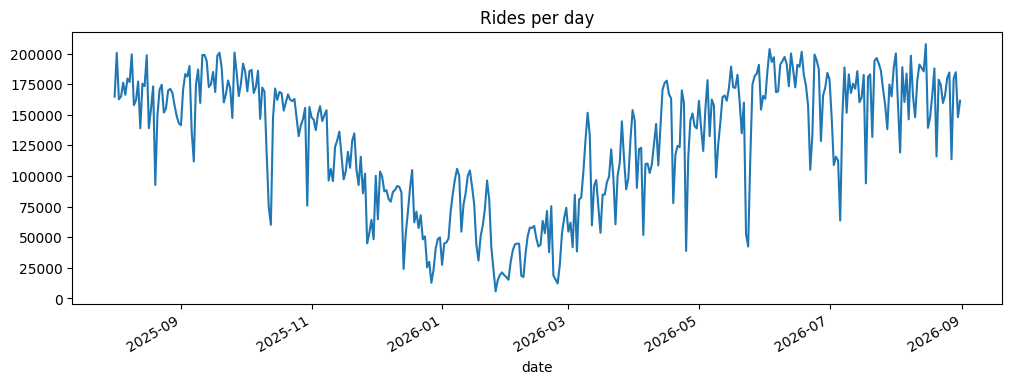

busiest day: 2026-08-15 00:00:00 207734.0
quietest day: 2026-01-26 00:00:00 5749.0


In [6]:
daily = station_day.groupby('date').agg(departures=('departures', 'sum'), tavg=('tavg', 'first'), prcp=('prcp', 'first'), is_weekend=('is_weekend', 'first'))

daily['departures'].plot(figsize=(12, 4))
plt.title('Rides per day')
plt.show()

print('busiest day:', daily['departures'].idxmax(), daily['departures'].max())
print('quietest day:', daily['departures'].idxmin(), daily['departures'].min())

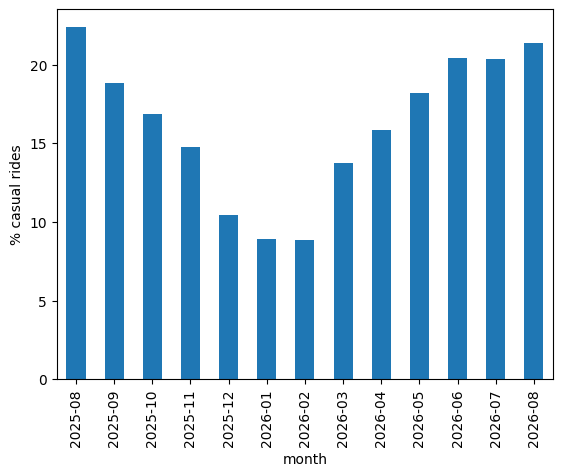

month
2025-08    22.4
2025-09    18.9
2025-10    16.8
2025-11    14.8
2025-12    10.4
2026-01     8.9
2026-02     8.8
2026-03    13.7
2026-04    15.8
2026-05    18.2
2026-06    20.4
2026-07    20.4
2026-08    21.4
Name: member_casual, dtype: float64

In [7]:
# share of casual riders by month
casual_month = trips.groupby('month')['member_casual'].apply(lambda x: (x == 'casual').mean() * 100)
casual_month.plot(kind='bar')
plt.ylabel('% casual rides')
plt.show()
casual_month.round(1)

About 208k rides on 15 August 2026 against 6k on 26 January 2026. Casual riders are 22% of the rides in September 2025 and only 9% in January and February.

## 1.3 Hours and days

The sample has 0.4% of the rides, so we multiply by 250 to get the real number of rides, and divide by the number of Mondays, Tuesdays... in the year.

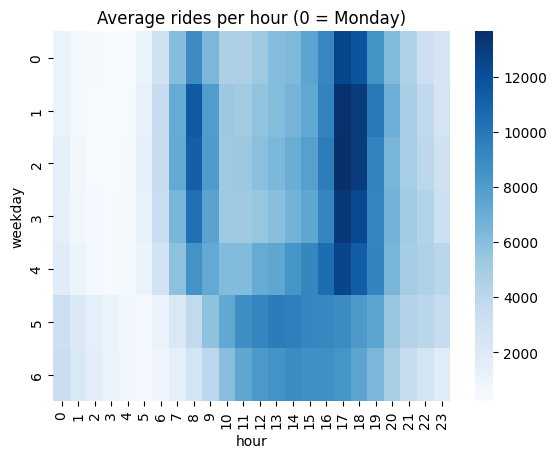

In [8]:
n_days = trips.groupby('weekday')['date'].nunique()
grid = trips.groupby(['weekday', 'hour']).size().unstack() * 250
grid = grid.div(n_days, axis=0)

sns.heatmap(grid, cmap='Blues')
plt.title('Average rides per hour (0 = Monday)')
plt.show()

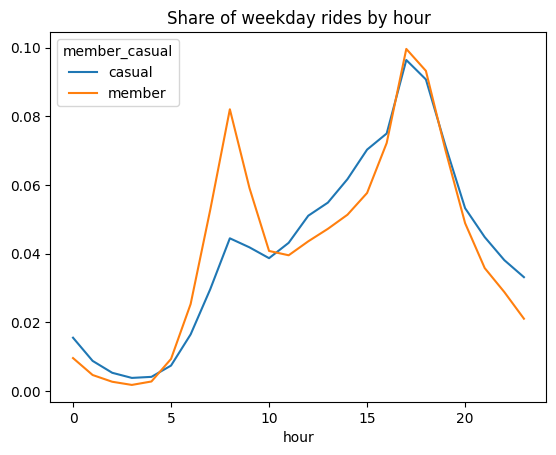

In [9]:
weekday_rides = trips[trips['is_weekend'] == False]
pd.crosstab(weekday_rides['hour'], weekday_rides['member_casual'], normalize='columns').plot()
plt.title('Share of weekday rides by hour')
plt.show()

On weekdays there are two peaks, 8am and 5-6pm, and only one around midday at the weekend. Members have a sharp morning peak (about 8% of their weekday rides at 8am), casual riders a flatter morning and a broad afternoon.

## 1.4 Where

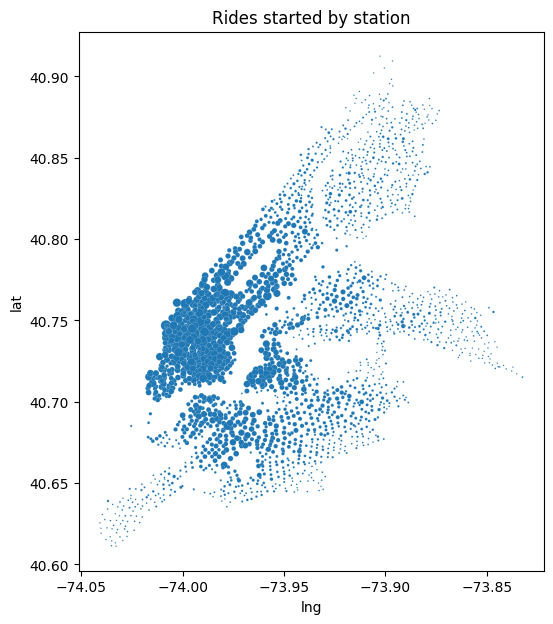

stations losing more than 300 bikes in the year: 277
stations gaining more than 300 bikes: 265


In [10]:
plt.figure(figsize=(6, 7))
sns.scatterplot(data=stations, x='lng', y='lat', size='departures', sizes=(1, 60), legend=False)
plt.title('Rides started by station')
plt.show()

print('stations losing more than 300 bikes in the year:', (stations['net_flow'] < -300).sum())
print('stations gaining more than 300 bikes:', (stations['net_flow'] > 300).sum())

In [11]:
dep_sorted = stations['departures'].sort_values(ascending=False)
print('share of rides of the busiest 10% of stations:', dep_sorted.head(231).sum() / dep_sorted.sum())
print('share of rides of the busiest 25% of stations:', dep_sorted.head(579).sum() / dep_sorted.sum())

share of rides of the busiest 10% of stations: 0.3848669505509859
share of rides of the busiest 25% of stations: 0.691791858204367


## 1.5 How concentrated are the shortages?

share of empty morning time in the 10% of stations most often empty: 0.46478329469844587


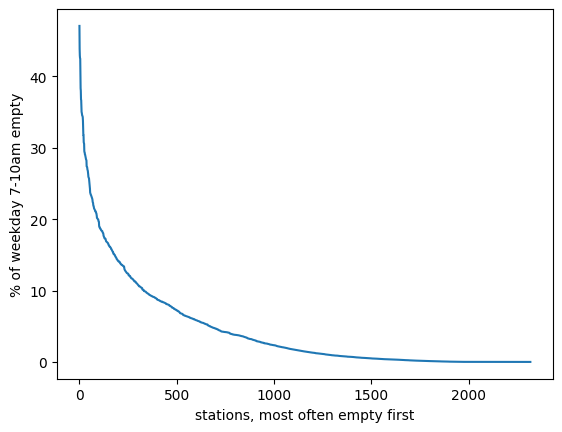

In [12]:
weekdays = station_day[station_day['is_weekend'] == False]
per_station = weekdays.groupby('station_name')['pct_empty_morning'].mean().sort_values(ascending=False)
print('share of empty morning time in the 10% of stations most often empty:', per_station.head(231).sum() / per_station.sum())

per_station.reset_index(drop=True).plot()
plt.ylabel('% of weekday 7-10am empty')
plt.xlabel('stations, most often empty first')
plt.show()

share of station-days empty at least 1 hour: 0.04707302495382292


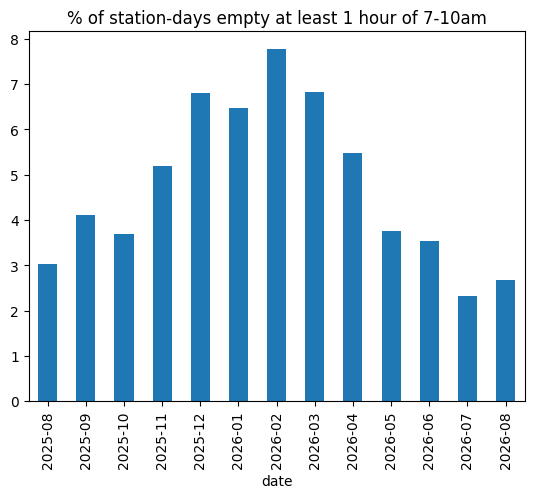

In [13]:
# empty for at least one hour of 7-10am = empty in at least 33% of the morning snapshots
station_day['empty_1h'] = station_day['pct_empty_morning'] >= 33
print('share of station-days empty at least 1 hour:', station_day['empty_1h'].mean())

(station_day.groupby(station_day['date'].dt.to_period('M'))['empty_1h'].mean() * 100).plot(kind='bar')
plt.title('% of station-days empty at least 1 hour of 7-10am')
plt.show()

In [14]:
station_day.groupby('weekday')['pct_empty_morning'].mean().round(1)

weekday
0    5.1
1    4.9
2    4.6
3    4.2
4    3.5
5    2.9
6    3.1
Name: pct_empty_morning, dtype: float64

10% of the stations make 46% of the empty time on weekday mornings. Shortages are more frequent in winter (7.8% of station-days in February against 3% in August) and on Monday (5.1% of the morning, 2.9% on Saturday). Only 4.7% of the station-days are empty for at least one hour: a model that always says "not empty" would be right 95.3% of the time, so later we use the AUC and not the accuracy.

## 1.6 Weather

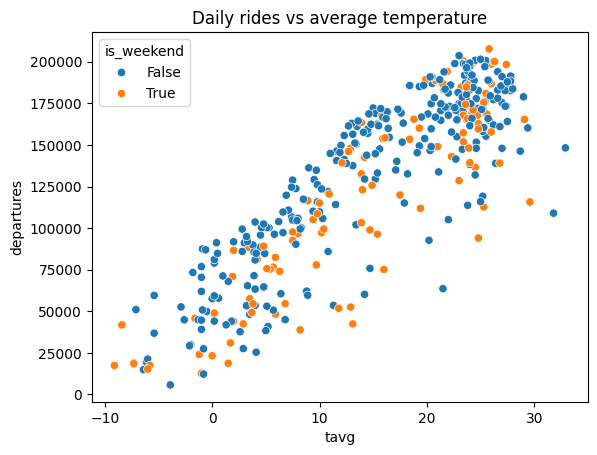

In [15]:
sns.scatterplot(data=daily, x='tavg', y='departures', hue='is_weekend')
plt.title('Daily rides vs average temperature')
plt.show()

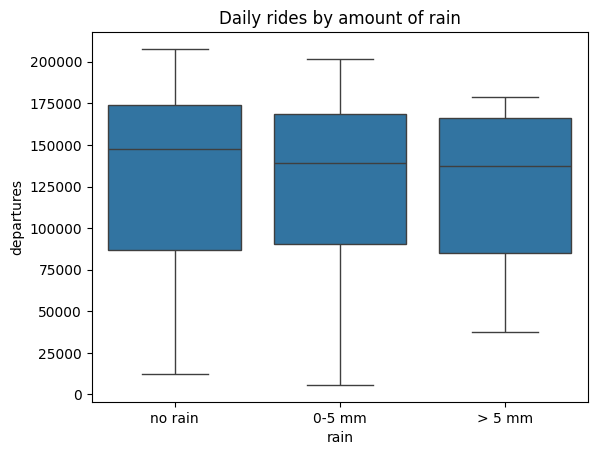

In [16]:
daily['rain'] = pd.cut(daily['prcp'], bins=[-1, 0, 5, 100], labels=['no rain', '0-5 mm', '> 5 mm'])
sns.boxplot(data=daily, x='rain', y='departures')
plt.title('Daily rides by amount of rain')
plt.show()

In [17]:
daily.groupby(daily.index.dayofweek)['departures'].mean().round()

date
0    120525.0
1    133031.0
2    135293.0
3    131297.0
4    137522.0
5    126470.0
6    112703.0
Name: departures, dtype: float64

Warm days have 3 to 4 times more rides than cold days. Looking at rain alone the boxes overlap a lot, because rainy days happen in every season and the temperature dominates. The regression in part 4 separates the two effects.

## 1.7 Members and casual riders

In [18]:
trips['member_casual'].value_counts(normalize=True)

member_casual
member    0.821922
casual    0.178078
Name: proportion, dtype: float64

In [19]:
trips.groupby('member_casual')[['duration_min', 'distance_km']].median()

,duration_min,distance_km
member_casual,,
casual,12.654233,1.725904
member,8.446967,1.470621


In [20]:
trips['ebike'] = trips['rideable_type'] == 'electric_bike'
trips.groupby('member_casual')[['ebike', 'is_weekend', 'round_trip']].mean().round(3)

,ebike,is_weekend,round_trip
member_casual,,,
casual,0.759,0.367,0.047
member,0.708,0.244,0.015


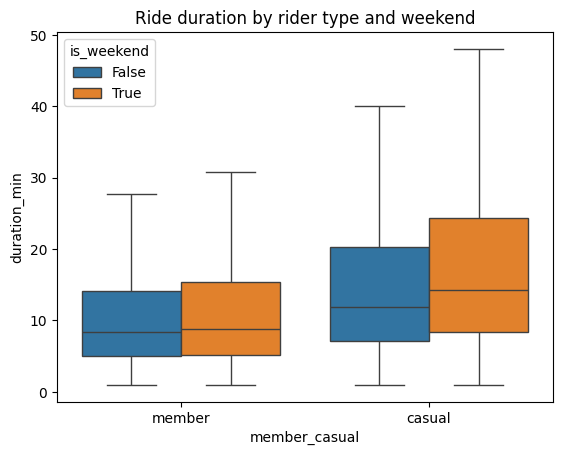

In [21]:
sns.boxplot(data=trips, x='member_casual', y='duration_min', hue='is_weekend', showfliers=False)
plt.title('Ride duration by rider type and weekend')
plt.show()

In [22]:
# weekday rides in the commuting peaks (7-10am and 4-8pm)
trips['commute_peak'] = (trips['is_weekend'] == False) & trips['period'].isin(['morning', 'evening'])
trips.groupby('member_casual')['commute_peak'].mean() * 100

member_casual
casual    28.432324
member    39.976920
Name: commute_peak, dtype: float64

Casual rides are longer (median 13 minutes against 8) and more often at the weekend (37% against 24%), but most of them are short. 28% of casual rides are made on weekdays in the commuting peaks, against 40% of member rides.

# 2. What riders say: topic model of the reviews (sessions 5.4 and 5.5)

In [23]:
print('average rating:', reviews['rating'].mean())
reviews['rating'].value_counts().sort_index()

average rating: 1.58


rating
1    362
2     65
3     25
4     17
5     31
Name: count, dtype: int64

362 of the 500 reviews give one star. People mostly write a review when something went wrong (the app has 4.5 stars over 10,193 ratings), so we use the reviews to see what annoys customers, not to measure satisfaction.

Same cleaning as in class: stopwords, punctuation, lemmatization.

In [24]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.stem.wordnet import WordNetLemmatizer
import string

stop = set(stopwords.words('english'))
exclude = set(string.punctuation)
lemma = WordNetLemmatizer()

def clean(doc):
    stop_free = " ".join([i for i in doc.lower().split() if i not in stop])
    punc_free = ''.join(ch for ch in stop_free if ch not in exclude)
    normalized = " ".join(lemma.lemmatize(word) for word in punc_free.split())
    return normalized

doc_complete = (reviews['title'].fillna('') + ' ' + reviews['content']).tolist()
doc_clean = [clean(doc).split() for doc in doc_complete]
print(doc_clean[0])

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/alessandrosimone/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/alessandrosimone/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/alessandrosimone/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


['gratitude', 'discount', 'program', 'deep', 'gratitude', 'appreciation', 'discount', 'provision', 'program', 'able', 'commute', 'exercise', 'visit', 'new', 'place', 'city', 'native', 'new', 'yorker', 'absolute', 'gem', 'i', 'donated', 'bicycle', 'local', 'high', 'school', 'carrying', 'upstairs', 'building', 'elevator', 'became', 'quite', 'difficult', 'thank', 'you', 'citibike', 'team', 'one', 'day', 'nationwide', 'maybe', 'international', 'program', 'transferable', 'membership', '💖👏🏽👏🏽✨']


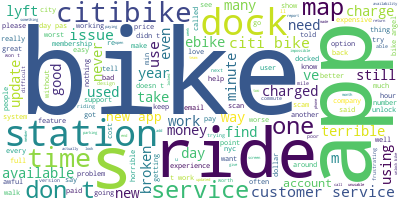

In [25]:
from wordcloud import WordCloud

long_string = ",".join([" ".join(sentence) for sentence in doc_clean])
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3, contour_color='steelblue')
wordcloud.generate(long_string)
wordcloud.to_image()

We remove words in fewer than 5 reviews and words in more than half of them (like "bike" and "app"), as suggested at the end of 5.4. Then we choose the number of topics with the coherence score (5.5).

num_topics = 2  coherence = 0.328


num_topics = 3  coherence = 0.2937


num_topics = 4  coherence = 0.3617


num_topics = 5  coherence = 0.3231


num_topics = 6  coherence = 0.3027


num_topics = 7  coherence = 0.3218


num_topics = 8  coherence = 0.3019


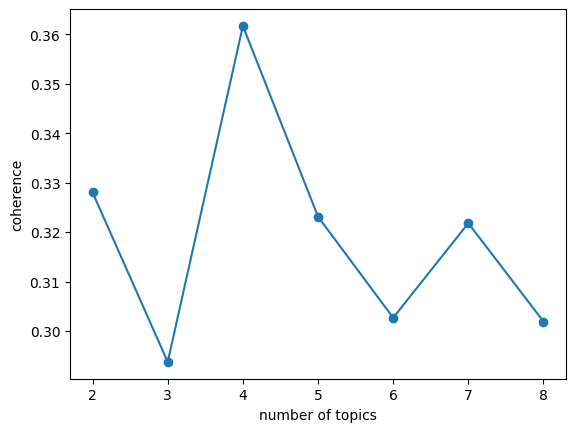

In [26]:
import gensim
from gensim import corpora
from gensim.models import CoherenceModel

dictionary = corpora.Dictionary(doc_clean)
dictionary.filter_extremes(no_below=5, no_above=0.5)
doc_term_matrix = [dictionary.doc2bow(doc) for doc in doc_clean]
Lda = gensim.models.ldamodel.LdaModel

coherence = []
for n in range(2, 9):
    m = Lda(doc_term_matrix, num_topics=n, id2word=dictionary, passes=10, random_state=42)
    c = CoherenceModel(model=m, texts=doc_clean, dictionary=dictionary, coherence='c_v').get_coherence()
    coherence.append(c)
    print('num_topics =', n, ' coherence =', round(c, 4))

plt.plot(range(2, 9), coherence, marker='o')
plt.xlabel('number of topics')
plt.ylabel('coherence')
plt.show()

In [27]:
lda_model = Lda(doc_term_matrix, num_topics=4, id2word=dictionary, passes=10, random_state=42)
for idx, topic in lda_model.print_topics(num_topics=4, num_words=8):
    print('Topic {}: \nWords: {}'.format(idx, topic), '\n')

Topic 0: 
Words: 0.040*"dock" + 0.028*"station" + 0.023*"service" + 0.014*"app" + 0.014*"full" + 0.013*"time" + 0.011*"customer" + 0.011*"available" 

Topic 1: 
Words: 0.024*"app" + 0.019*"service" + 0.018*"get" + 0.016*"ride" + 0.015*"time" + 0.014*"customer" + 0.013*"use" + 0.012*"don’t" 

Topic 2: 
Words: 0.030*"day" + 0.022*"app" + 0.021*"charged" + 0.018*"pas" + 0.017*"work" + 0.015*"time" + 0.015*"money" + 0.014*"minute" 

Topic 3: 
Words: 0.055*"app" + 0.022*"new" + 0.019*"map" + 0.018*"lyft" + 0.018*"ride" + 0.016*"update" + 0.014*"citibike" + 0.012*"get" 



4 topics has the best coherence (0.36). Reading the words: topic 0 is about docks and stations (no dock to return the bike, no bike), topic 1 customer service, topic 2 pricing and charges (day pass, extra minutes) and topic 3 the app and the map. "pas" is "pass" after lemmatization.

In [28]:
topic_names = {0: 'Docks & stations', 1: 'Customer service', 2: 'Pricing & charges', 3: 'App & map'}

# main topic of a review = topic with the highest probability
main_topic = []
for bow in doc_term_matrix:
    probs = lda_model.get_document_topics(bow, minimum_probability=0)
    main_topic.append(max(probs, key=lambda x: x[1])[0])
reviews['topic'] = pd.Series(main_topic).map(topic_names)

reviews.groupby('topic').agg(reviews=('rating', 'size'), rating=('rating', 'mean')).round(2)

,reviews,rating
topic,,
App & map,173,1.83
Customer service,170,1.38
Docks & stations,98,1.62
Pricing & charges,59,1.36


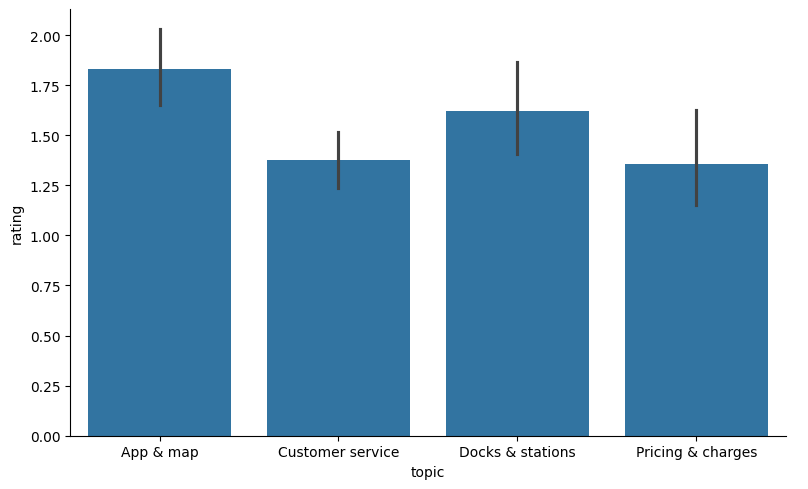

,date,rating,content
5,2026-09-21,5,Quicker and cheaper than uber when you need to...
8,2026-09-19,1,This app is awful and all the docking stations...
12,2026-09-16,5,Need to move bikes and repair them more often 🙏
13,2026-09-15,2,Not cool
17,2026-09-11,3,Reps May Not Enjoy Their Jobs


In [29]:
sns.catplot(data=reviews, x='topic', y='rating', kind='bar', aspect=1.6)
plt.show()

reviews[reviews['topic'] == 'Docks & stations'][['date', 'rating', 'content']].head()

About one review in five (98 of 500) is mainly about docks and stations: customers see the rebalancing problem directly. The ratings are low for every topic and the confidence intervals overlap.

# 3. Four types of stations: PCA and k-means (sessions 5.2, 5.3, 5.6)

Each station has a weekday "personality": at which hours bikes leave and at which hours they arrive. In `stations.csv` these are 48 columns (`dep_0` to `dep_23` and `arr_0` to `arr_23`). As in 5.6 we scale them and reduce them with PCA, then we cluster the stations with k-means and give a name to each cluster as in 5.3.

In [30]:
dep_cols = ['dep_' + str(h) for h in range(24)]
arr_cols = ['arr_' + str(h) for h in range(24)]

X_scaled = StandardScaler().fit_transform(stations[dep_cols + arr_cols])

pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(X_scaled.shape, '->', X_pca.shape)
print(pca.explained_variance_ratio_.round(3))

(2318, 48) -> (2318, 27)
[0.21  0.128 0.101 0.075 0.059 0.031 0.028 0.026 0.02  0.019 0.018 0.016
 0.015 0.014 0.014 0.014 0.013 0.012 0.012 0.011 0.01  0.01  0.01  0.009
 0.009 0.009 0.008]


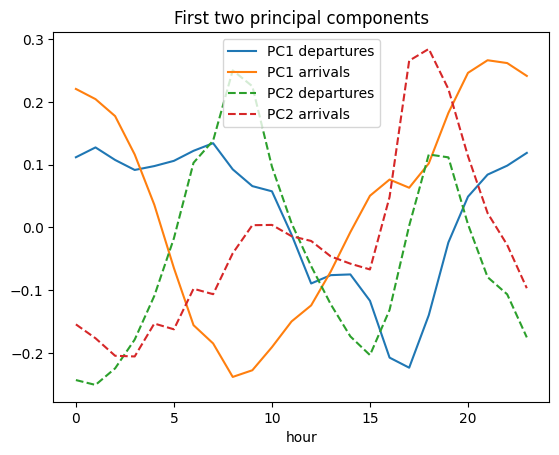

In [31]:
plt.plot(range(24), pca.components_[0][:24], label='PC1 departures')
plt.plot(range(24), pca.components_[0][24:], label='PC1 arrivals')
plt.plot(range(24), pca.components_[1][:24], label='PC2 departures', linestyle='--')
plt.plot(range(24), pca.components_[1][24:], label='PC2 arrivals', linestyle='--')
plt.xlabel('hour')
plt.legend()
plt.title('First two principal components')
plt.show()

27 components keep 90% of the variance. PC1 (21%) is mostly about when bikes arrive, in the morning (offices) or in the evening (homes). PC2 (13%) is about how strong the commuting pattern is.

## 3.1 How many clusters?

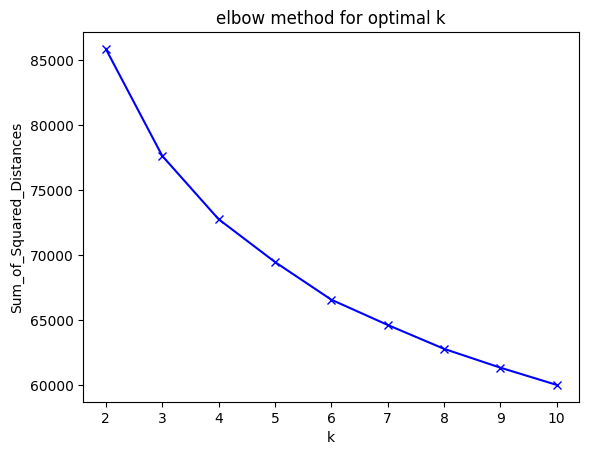

In [32]:
sum_of_squared_distances = []
K = range(2, 11)
for k in K:
    k_means = KMeans(n_clusters=k, random_state=42, n_init=10)
    model = k_means.fit(X_pca)
    sum_of_squared_distances.append(k_means.inertia_)

plt.plot(K, sum_of_squared_distances, 'bx-')
plt.xlabel('k')
plt.ylabel('Sum_of_Squared_Distances')
plt.title('elbow method for optimal k')
plt.show()

k = 2 , Silhouette Score: 0.1504
k = 3 , Silhouette Score: 0.1291


k = 4 , Silhouette Score: 0.1121
k = 5 , Silhouette Score: 0.0870


k = 6 , Silhouette Score: 0.0905
k = 7 , Silhouette Score: 0.0834


k = 8 , Silhouette Score: 0.0870
k = 9 , Silhouette Score: 0.0872


k = 10 , Silhouette Score: 0.0732


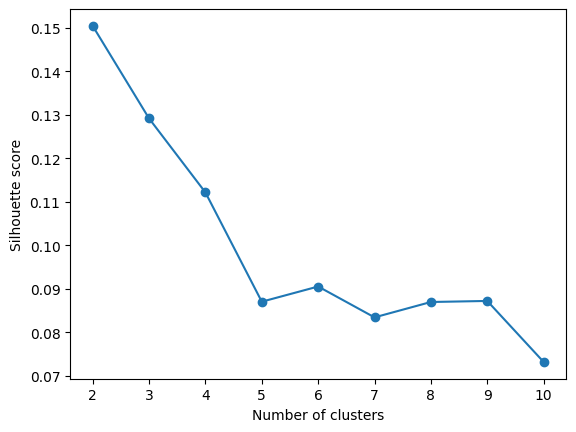

In [33]:
silhouette_scores = []
for k in range(2, 11):
    k_means_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = k_means_k.fit_predict(X_pca)
    silhouette_score = metrics.silhouette_score(X_pca, labels_k, metric='euclidean')
    silhouette_scores.append(silhouette_score)
    print('k =', k, ', Silhouette Score: {:.4f}'.format(silhouette_score))

plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.show()

There is no clear elbow, and the silhouette is low and falls from 0.15 (k = 2) to 0.11 (k = 4): the stations are more a continuum than separate groups. k = 2 only separates busy and quiet stations, so we take k = 4, which gives four types we can name and act on. It is a business choice, not something the statistics impose.

In [34]:
k_means_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
stations['cluster'] = k_means_4.fit_predict(X_pca)
stations['cluster'].value_counts()

cluster
2    842
1    628
3    511
0    337
Name: count, dtype: int64

## 3.2 Reading the clusters

The centroids are in PCA units, which are hard to read, so we plot the average 24-hour profile of each cluster.

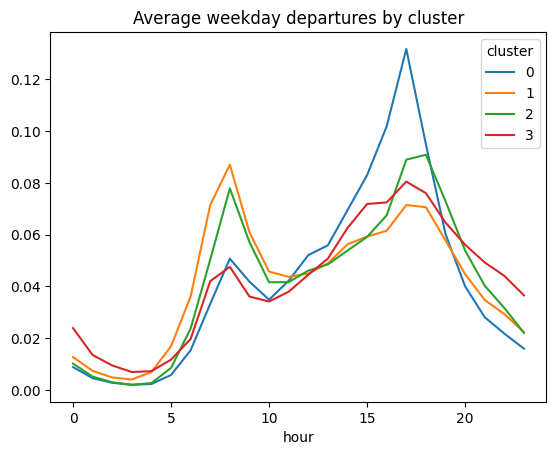

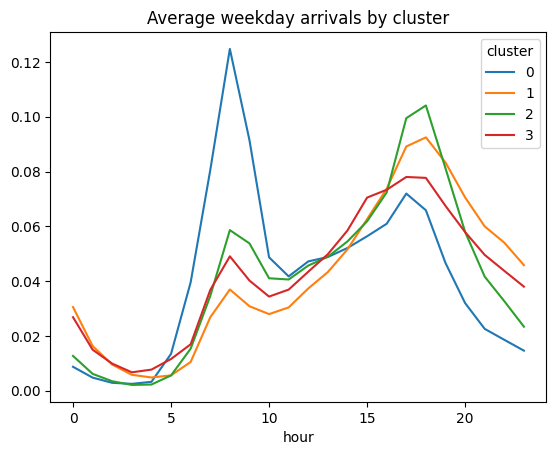

In [35]:
stations.groupby('cluster')[dep_cols].mean().T.reset_index(drop=True).plot()
plt.title('Average weekday departures by cluster')
plt.xlabel('hour')
plt.show()

stations.groupby('cluster')[arr_cols].mean().T.reset_index(drop=True).plot()
plt.title('Average weekday arrivals by cluster')
plt.xlabel('hour')
plt.show()

In [36]:
stations.groupby('cluster')[['departures', 'net_flow', 'capacity', 'casual_share', 'round_trip_share', 'avg_duration', 'lat', 'lng']].mean().round(3)

,departures,net_flow,capacity,casual_share,round_trip_share,avg_duration,lat,lng
cluster,,,,,,,,
0,31268.513,-10.288,43.033,0.201,0.031,13.504,40.749,-73.963
1,10353.229,-76.732,24.473,0.212,0.036,12.421,40.740,-73.925
2,36017.289,78.563,36.949,0.184,0.027,12.793,40.727,-73.969
3,6299.051,-39.088,22.763,0.242,0.049,12.816,40.778,-73.912


Cluster 0: arrivals peak in the morning and departures in the evening, large stations in Midtown, so work stations. Cluster 1 is the mirror image, departures in the morning and arrivals in the evening, and these stations lose bikes over the year: residential stations. Cluster 2 has the busiest stations with both peaks (downtown, north Brooklyn): busy mixed. Cluster 3 has few rides, a flatter profile and the most casual riders: low demand.

In [37]:
cluster_names = {0: 'Work (morning arrivals)', 1: 'Residential (morning departures)', 2: 'Busy mixed', 3: 'Low demand / leisure'}
stations['segment'] = stations['cluster'].map(cluster_names)

# rides per day over the 396 days
segment_table = stations.groupby('segment').agg(stations=('station_name', 'count'), departures=('departures', 'mean'), capacity=('capacity', 'mean'),
                                                casual_share=('casual_share', 'mean'), net_flow=('net_flow', 'mean'))
segment_table['rides_per_day'] = segment_table['departures'] / 396
segment_table.round(2)

,stations,departures,capacity,casual_share,net_flow,rides_per_day
segment,,,,,,
Busy mixed,842,36017.29,36.95,0.18,78.56,90.95
Low demand / leisure,511,6299.05,22.76,0.24,-39.09,15.91
Residential (morning departures),628,10353.23,24.47,0.21,-76.73,26.14
Work (morning arrivals),337,31268.51,43.03,0.20,-10.29,78.96


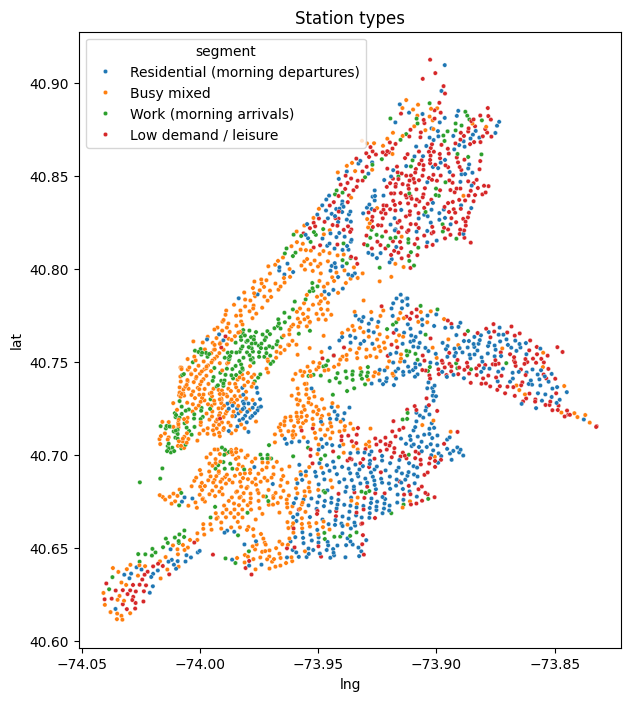

In [38]:
plt.figure(figsize=(7, 8))
sns.scatterplot(data=stations, x='lng', y='lat', hue='segment', s=10)
plt.title('Station types')
plt.show()

k-means never saw the coordinates, but the types make sense on the map: residential in upper Manhattan, Brooklyn and Queens, work in Midtown and the Financial District.

Residential stations send out 8.7% of their weekday departures between 8 and 9am, and work stations receive 12.5% of their arrivals in the same hour:

In [39]:
print(stations[stations['segment'] == 'Residential (morning departures)']['dep_8'].mean())
print(stations[stations['segment'] == 'Work (morning arrivals)']['arr_8'].mean())

0.08705175159235667
0.1247433234421365


## 3.3 Which types run empty or full? (as the churn per cluster in 5.3)

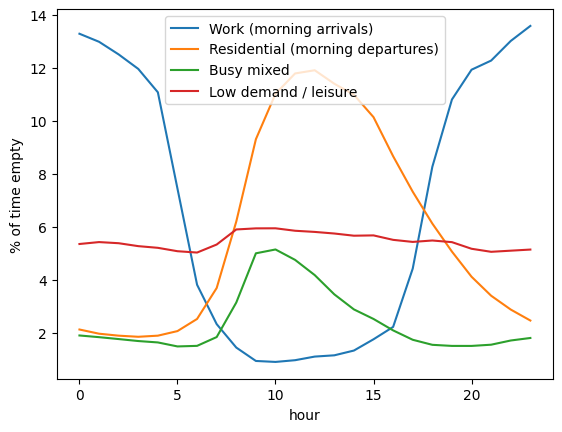

In [40]:
station_day = station_day.merge(stations[['station_name', 'segment']], on='station_name')

for seg in cluster_names.values():
    rows = stations[stations['segment'] == seg]
    plt.plot(range(24), rows[['empty_' + str(h) for h in range(24)]].mean().values, label=seg)
plt.xlabel('hour')
plt.ylabel('% of time empty')
plt.legend()
plt.show()

In [41]:
station_day[station_day['is_weekend'] == False].groupby('segment')[['pct_empty_morning', 'pct_full_morning', 'pct_empty_evening', 'pct_full_evening']].mean().round(1)

,pct_empty_morning,pct_full_morning,pct_empty_evening,pct_full_evening
segment,,,,
Busy mixed,3.3,5.5,1.7,7.2
Low demand / leisure,6.0,6.7,5.5,6.7
Residential (morning departures),6.4,3.5,6.8,3.0
Work (morning arrivals),1.6,10.4,6.2,3.9


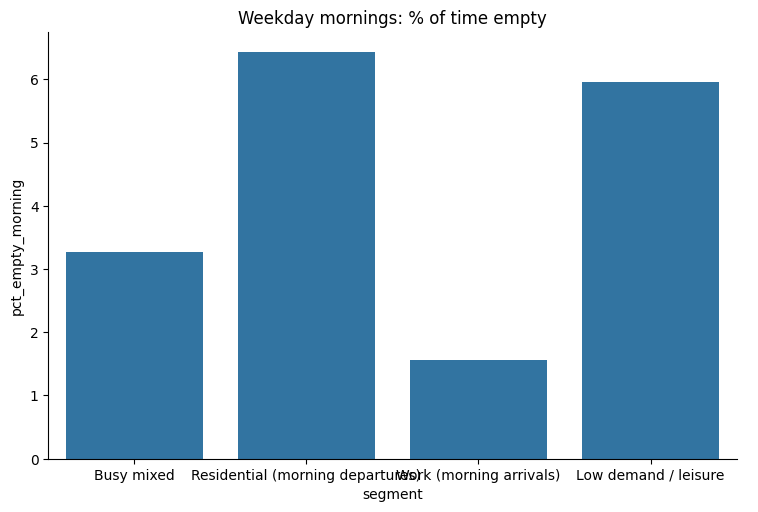

In [42]:
sns.catplot(data=station_day[station_day['is_weekend'] == False], x='segment', y='pct_empty_morning', kind='bar', errorbar=None, aspect=1.5)
plt.title('Weekday mornings: % of time empty')
plt.show()

On weekday mornings residential stations are empty 6.4% of the time, four times more than work stations (1.6%), while work stations are full 10.4% of the time. At night it is the opposite: work stations are often empty and residential stations often full. Low-demand stations are both empty (6.0%) and full (6.7%) quite often.

# 4. What drives demand: linear regression (sessions 2.3, 3.1, 4.1)

Target: departures of a station on a day. Variables: calendar (day of the week, month, holiday), weather, station (capacity, type) and the departures of the same station one week before.

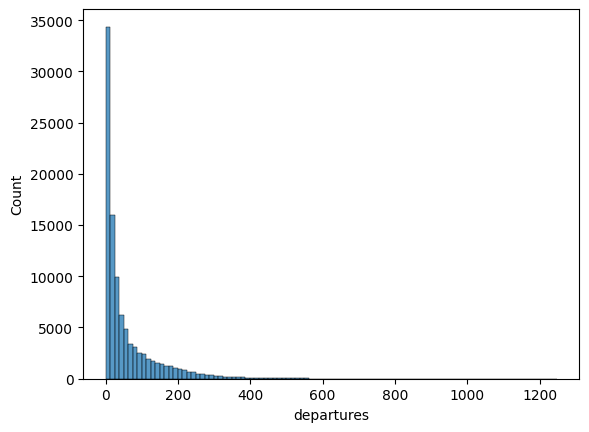

In [43]:
last_week = station_day[['station_name', 'date', 'departures']].copy()
last_week['date'] = last_week['date'] + pd.Timedelta(days=7)
last_week.columns = ['station_name', 'date', 'departures_last_week']
station_day = station_day.merge(last_week, on=['station_name', 'date'], how='left')

# 100,000 station-days are enough for a linear model
reg = station_day.dropna(subset=['departures_last_week', 'tavg', 'prcp']).sample(100000, random_state=42)

sns.histplot(data=reg, x='departures', bins=100)
plt.show()

Very skewed, so as in 2.3 we take the log. Some days have 0 departures, so we use log(1 + departures) with `np.log1p`.

In [44]:
reg['log_departures'] = np.log1p(reg['departures'])
reg['log_departures_last_week'] = np.log1p(reg['departures_last_week'])

X_reg = pd.get_dummies(reg[['weekday', 'month', 'holiday', 'tavg', 'prcp', 'wspd', 'capacity', 'segment', 'log_departures_last_week']],
                       columns=['weekday', 'month', 'segment'], drop_first=True, dtype='int')
Y_reg = reg['log_departures']

Xtrain, Xtest, Ytrain, Ytest = train_test_split(X_reg, Y_reg, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(Xtrain, Ytrain)
Ypred = model.predict(Xtest)

print('in-sample R squared:', model.score(Xtrain, Ytrain))
print('out-of-sample R squared:', model.score(Xtest, Ytest))
print('RMSE (log units):', np.sqrt(mean_squared_error(Ytest, Ypred)))

in-sample R squared: 0.850165645468677
out-of-sample R squared: 0.8492104786899892
RMSE (log units): 0.5408635190932146


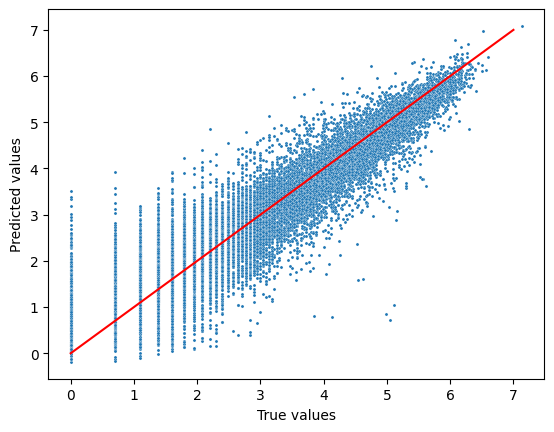

In [45]:
fig = sns.scatterplot(x=Ytest, y=Ypred, s=5)
fig.set(xlabel='True values', ylabel='Predicted values')
fig.plot([0, 7], [0, 7], '-r')
plt.show()

In [46]:
# same model without the log
model_levels = LinearRegression().fit(Xtrain, np.expm1(Ytrain))
print('R squared, departures in levels:', model_levels.score(Xtest, np.expm1(Ytest)))

R squared, departures in levels: 0.6416592565633126


In [47]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=10)
cv_linear_r2 = cross_val_score(LinearRegression(), Xtrain, Ytrain, cv=cv5)
print(cv_linear_r2)
print('Average performance score:', cv_linear_r2.mean())

[0.84681819 0.85430725 0.85088534 0.85065048 0.84749493]
Average performance score: 0.8500312367915541


R squared 0.85 on the test set (0.64 without the log), and 0.850 in 5-fold cross-validation, so it does not depend on the split.

## 4.1 Effects of the variables

The target is in log, so exp(coefficient) - 1 is the % change in rides.

In [48]:
coefs = pd.Series(model.coef_, index=X_reg.columns)
print('+1 degree:', np.exp(coefs['tavg']) - 1)
print('+1 mm of rain:', np.exp(coefs['prcp']) - 1)
print('+1 km/h of wind:', np.exp(coefs['wspd']) - 1)
print('public holiday:', np.exp(coefs['holiday']) - 1)
print('Saturday vs Monday:', np.exp(coefs['weekday_5']) - 1)
print('Sunday vs Monday:', np.exp(coefs['weekday_6']) - 1)
print('+10% rides one week before:', np.exp(coefs['log_departures_last_week'] * np.log(1.1)) - 1)
coefs.sort_values()

+1 degree: 0.0349688546503546
+1 mm of rain: -0.012185914819280552
+1 km/h of wind: -0.006392072398726523
public holiday: -0.23833201479804533
Saturday vs Monday: -0.02997034722268499
Sunday vs Monday: -0.03576313883077886
+10% rides one week before: 0.07983272654797102


month_7                                    -0.573703
month_8                                    -0.540048
month_6                                    -0.485348
month_9                                    -0.398446
holiday                                    -0.272245
month_10                                   -0.254351
month_5                                    -0.252292
segment_Low demand / leisure               -0.214123
month_4                                    -0.191240
month_11                                   -0.161910
segment_Residential (morning departures)   -0.149405
segment_Work (morning arrivals)            -0.123151
month_12                                   -0.062904
weekday_6                                  -0.036418
weekday_5                                  -0.030429
weekday_2                                  -0.019800
weekday_3                                  -0.012347
prcp                                       -0.012261
wspd                                       -0.

+1 degree gives 3.5% more rides, each mm of rain 1.2% fewer, a public holiday 23.8% fewer. A station with 10% more rides last week has 8% more rides today (the coefficient of the log-log term is an elasticity, about 0.81).

## 4.2 Does time explain demand better than the station? (H1)

Same regression with one group of variables at a time, out-of-sample R squared.

In [49]:
time_cols = [c for c in X_reg.columns if c.startswith('weekday') or c.startswith('month') or c == 'holiday']
weather_cols = ['tavg', 'prcp', 'wspd']
station_cols = ['capacity'] + [c for c in X_reg.columns if c.startswith('segment')]

m = LinearRegression().fit(Xtrain[time_cols], Ytrain)
print('calendar only:', m.score(Xtest[time_cols], Ytest))

m = LinearRegression().fit(Xtrain[weather_cols], Ytrain)
print('weather only:', m.score(Xtest[weather_cols], Ytest))

m = LinearRegression().fit(Xtrain[time_cols + weather_cols], Ytrain)
print('calendar + weather:', m.score(Xtest[time_cols + weather_cols], Ytest))

m = LinearRegression().fit(Xtrain[station_cols], Ytrain)
print('station only:', m.score(Xtest[station_cols], Ytest))

m = LinearRegression().fit(Xtrain[station_cols + ['log_departures_last_week']], Ytrain)
print('station + last week:', m.score(Xtest[station_cols + ['log_departures_last_week']], Ytest))

print('all variables:', model.score(Xtest, Ytest))

calendar only: 0.11570533562591823


weather only: 0.11481414622023012
calendar + weather: 0.12809595033726784
station only: 0.4404071385055448
station + last week: 0.8294525195898357
all variables: 0.8492104786899892


For a station, the calendar alone explains 12% and the weather 11%, while knowing which station it is explains 44%, and 83% with last week's rides. So H1 is not true at station level. For the whole city it is different, as the regression on the daily totals shows:

In [50]:
d = daily.dropna().reset_index()
d['weekday'] = d['date'].dt.dayofweek
Xd = pd.get_dummies(d[['weekday', 'tavg', 'prcp']], columns=['weekday'], drop_first=True, dtype='int')
yd = np.log(d['departures'])
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.2, random_state=42)

weekday_cols = [c for c in Xd.columns if c.startswith('weekday')]
m = LinearRegression().fit(Xd_train[weekday_cols], yd_train)
print('city, weekday only:', m.score(Xd_test[weekday_cols], yd_test))
m = LinearRegression().fit(Xd_train[['tavg', 'prcp']], yd_train)
print('city, weather only:', m.score(Xd_test[['tavg', 'prcp']], yd_test))
m = LinearRegression().fit(Xd_train, yd_train)
print('city, weekday + weather:', m.score(Xd_test, yd_test))

city, weekday only: 0.006621991928197457
city, weather only: 0.774877990392356
city, weekday + weather: 0.7774320631705879


For the city the weather explains 78% of the daily rides and the day of the week almost nothing. The weather sets the volume of the whole system but says little about which station will be short.

## 4.3 Feature selection: stepwise and Lasso (3.1)

In [51]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

Xs, Ys = Xtrain.iloc[:20000], Ytrain.iloc[:20000]

sfs1 = SFS(LinearRegression(), k_features=5, forward=True, floating=False, verbose=0, scoring='r2', cv=0)
sfs1 = sfs1.fit(Xs, Ys)
print('forward:', sfs1.k_feature_names_, round(sfs1.k_score_, 3))

sfs2 = SFS(LinearRegression(), k_features=5, forward=False, floating=False, verbose=0, scoring='r2', cv=0)
sfs2 = sfs2.fit(Xs, Ys)
print('backward:', sfs2.k_feature_names_, round(sfs2.k_score_, 3))

forward: ('tavg', 'prcp', 'capacity', 'log_departures_last_week', 'month_3') 0.84


backward: ('tavg', 'prcp', 'capacity', 'log_departures_last_week', 'month_3') 0.84


In [52]:
scaler = StandardScaler().fit(Xtrain)
Xtrain_s = scaler.transform(Xtrain)
Xtest_s = scaler.transform(Xtest)

lasso_model = Lasso(alpha=0.01, random_state=42)
lasso_model.fit(Xtrain_s, Ytrain)
for feature, coef in zip(X_reg.columns, lasso_model.coef_):
    print(f"{feature}: {coef:.4f}")
print('features kept by Lasso:', (lasso_model.coef_ != 0).sum(), '/', len(lasso_model.coef_))
print('Lasso out-of-sample R squared:', lasso_model.score(Xtest_s, Ytest))

holiday: -0.0345
tavg: 0.1679
prcp: -0.0452
wspd: -0.0287
capacity: 0.1251
log_departures_last_week: 1.1248
weekday_1: 0.0000
weekday_2: 0.0000
weekday_3: 0.0000
weekday_4: 0.0000
weekday_5: -0.0000
weekday_6: -0.0000
month_2: 0.0359
month_3: 0.0599
month_4: 0.0000
month_5: 0.0054
month_6: -0.0118
month_7: -0.0277
month_8: -0.0284
month_9: -0.0000
month_10: 0.0000
month_11: 0.0000
month_12: -0.0000
segment_Low demand / leisure: -0.0686
segment_Residential (morning departures): -0.0465
segment_Work (morning arrivals): -0.0224
features kept by Lasso: 15 / 26
Lasso out-of-sample R squared: 0.8465619909419482


In [53]:
ridge_model = Ridge(alpha=0.1, random_state=42)
ridge_model.fit(Xtrain_s, Ytrain)
print('Ridge out-of-sample R squared:', ridge_model.score(Xtest_s, Ytest))

Ridge out-of-sample R squared: 0.8492105086692584


In [54]:
# Lasso with a bigger and bigger penalty
for a in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]:
    las = Lasso(alpha=a, random_state=42).fit(Xtrain_s, Ytrain)
    print('alpha =', a, ' variables kept:', (las.coef_ != 0).sum(), ' R squared:', round(las.score(Xtest_s, Ytest), 3))

alpha = 0.001  variables kept: 26  R squared: 0.849


alpha = 0.003  variables kept: 19  R squared: 0.848
alpha = 0.01  variables kept: 15  R squared: 0.847
alpha = 0.03  variables kept: 9  R squared: 0.84


alpha = 0.1  variables kept: 3  R squared: 0.825


alpha = 0.3  variables kept: 1  R squared: 0.779


Forward and backward stepwise pick the same 5 variables (temperature, rain, capacity, last week's rides and March). Lasso with alpha = 0.01 keeps 15 of the 26 variables with almost the same R squared (0.847 against 0.849) and puts all the day-of-week dummies at 0: once we know last week's rides on the same weekday, the day adds nothing. Ridge and OLS give the same R squared, there is no overfitting with 100,000 rows.

# 5. Who rides: members vs casual riders (sessions 3.2, 3.3, 4.2, 4.3, 4.4)

Can we tell a casual rider from a member only from the ride? Target: casual = 1.

In [55]:
trips = trips.merge(stations[['station_name', 'segment']], left_on='start_station_name', right_on='station_name', how='left')
trips = trips.dropna(subset=['segment', 'tavg', 'prcp'])

Y = (trips['member_casual'] == 'casual').astype(int)
Y.value_counts()

member_casual
0    164452
1     35724
Name: count, dtype: int64

In [56]:
X = pd.get_dummies(trips[['duration_min', 'distance_km', 'hour', 'is_weekend', 'holiday', 'round_trip', 'rideable_type', 'tavg', 'prcp', 'segment']],
                   columns=['rideable_type', 'segment'], dtype='int')
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
X.head()

,duration_min,distance_km,hour,is_weekend,holiday,round_trip,tavg,prcp,rideable_type_classic_bike,rideable_type_electric_bike,segment_Busy mixed,segment_Low demand / leisure,segment_Residential (morning departures),segment_Work (morning arrivals)
0,11.011017,2.443089,7,False,False,False,23.8,1.1,0,1,1,0,0,0
1,9.714683,0.847103,8,False,False,False,22.3,1.5,1,0,1,0,0,0
2,13.590400,3.647267,17,False,False,False,23.1,0.0,0,1,0,1,0,0
3,16.203117,2.426017,15,True,False,False,26.8,1.4,1,0,0,0,0,1
4,10.005567,1.094012,10,True,False,False,23.4,0.0,1,0,1,0,0,0


Only 18% of the rides are casual, so a model that always says "member" is already 82% accurate. We look at recall, F1 and AUC.

## 5.1 Logistic regression (3.2)

In [57]:
log_clf = LogisticRegression(max_iter=1000)
log_clf.fit(X_train, y_train)
predicted_y = log_clf.predict(X_test)
print('Prediction Accuracy: {:.4f}'.format(log_clf.score(X_test, y_test)))
print(classification_report(y_test, predicted_y))

Prediction Accuracy: 0.8239
              precision    recall  f1-score   support

           0       0.83      0.99      0.90     32894
           1       0.55      0.07      0.13      7142

    accuracy                           0.82     40036
   macro avg       0.69      0.53      0.52     40036
weighted avg       0.78      0.82      0.76     40036



In [58]:
# positive = more likely to be casual
pd.Series(log_clf.coef_[0], index=X.columns).sort_values()

rideable_type_classic_bike                 -1.001966
rideable_type_electric_bike                -0.588195
segment_Busy mixed                         -0.486708
segment_Residential (morning departures)   -0.433945
segment_Work (morning arrivals)            -0.374591
segment_Low demand / leisure               -0.294916
distance_km                                -0.176958
prcp                                       -0.009165
hour                                        0.007433
tavg                                        0.029588
duration_min                                0.056078
holiday                                     0.303312
round_trip                                  0.435110
is_weekend                                  0.515789
dtype: float64

Accuracy 82%, the same as always saying "member", and only 7% of casual riders found. The signs make sense: weekend, holiday, round trip and longer rides go with casual riders, longer distance with members.

## 5.2 Naive Bayes (3.3) and decision tree (4.2)

In [59]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)
print(classification_report(y_test, gnb.predict(X_test)))

              precision    recall  f1-score   support

           0       0.84      0.94      0.89     32894
           1       0.37      0.16      0.23      7142

    accuracy                           0.80     40036
   macro avg       0.60      0.55      0.56     40036
weighted avg       0.75      0.80      0.77     40036



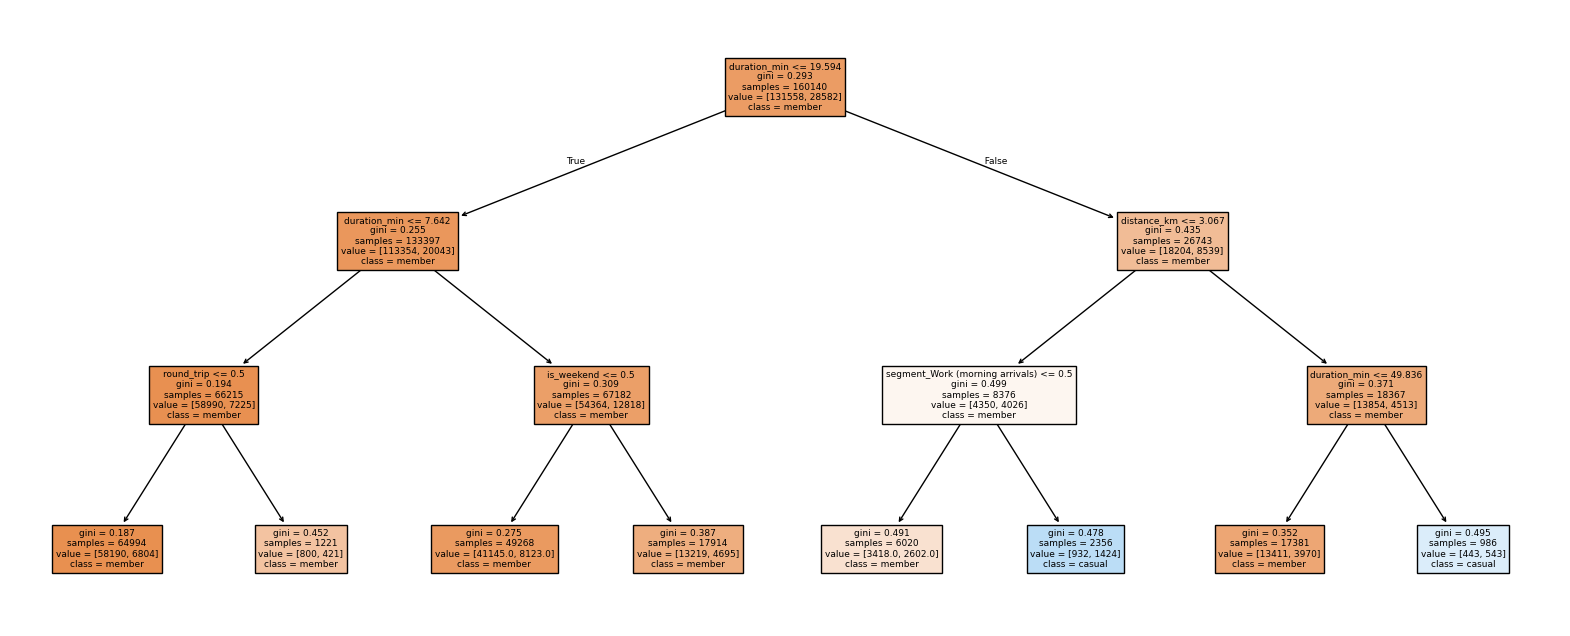

              precision    recall  f1-score   support

           0       0.83      0.99      0.90     32894
           1       0.52      0.06      0.10      7142

    accuracy                           0.82     40036
   macro avg       0.67      0.52      0.50     40036
weighted avg       0.77      0.82      0.76     40036



In [60]:
from sklearn import tree

tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf.fit(X_train, y_train)

plt.figure(figsize=(20, 8))
tree.plot_tree(tree_clf, feature_names=list(X.columns), class_names=['member', 'casual'], filled=True)
plt.show()
print(classification_report(y_test, tree_clf.predict(X_test)))

The first split is duration below 19.6 minutes: short rides are almost all members. Casual riders are the majority only for rides longer than 50 minutes, or longer than 19.6 minutes and shorter than 3 km from a work station (tourists in Midtown).

## 5.3 Random forest and ROC curves (4.2)

              precision    recall  f1-score   support

           0       0.83      0.99      0.90     32894
           1       0.61      0.08      0.15      7142

    accuracy                           0.83     40036
   macro avg       0.72      0.54      0.52     40036
weighted avg       0.79      0.83      0.77     40036



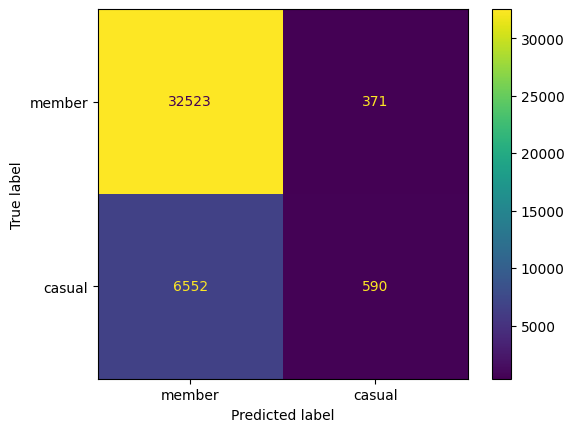

In [61]:
# min_samples_leaf=20: each leaf has at least 20 rides, against overfitting
rf_classifier = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=42)
rf_classifier.fit(X_train, y_train)
y_preds = rf_classifier.predict(X_test)
print(classification_report(y_test, y_preds))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_preds), display_labels=['member', 'casual']).plot()
plt.show()

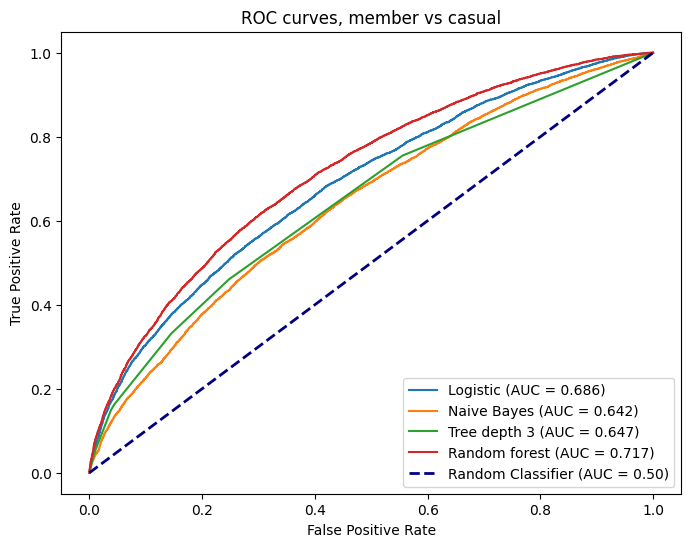

In [62]:
plt.figure(figsize=(8, 6))

fpr, tpr, thresholds = roc_curve(y_test, log_clf.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, label=f'Logistic (AUC = {auc(fpr, tpr):.3f})')
fpr, tpr, thresholds = roc_curve(y_test, gnb.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, label=f'Naive Bayes (AUC = {auc(fpr, tpr):.3f})')
fpr, tpr, thresholds = roc_curve(y_test, tree_clf.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, label=f'Tree depth 3 (AUC = {auc(fpr, tpr):.3f})')
fpr, tpr, thresholds = roc_curve(y_test, rf_classifier.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, label=f'Random forest (AUC = {auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves, member vs casual')
plt.legend(loc='lower right')
plt.show()

The random forest is the best (AUC 0.72), then logistic regression (0.69), the tree (0.65) and Naive Bayes (0.64). Better than random but weak.

## 5.4 KNN and the choice of k

We use KNN to show the bias-variance trade-off of 4.1. With small k the model copies the training rides (overfitting), with large k it averages too much (underfitting). KNN uses distances so we standardise, and it is slow, so we train it on 20,000 rides.

k = 1  train AUC = 1.0  test AUC = 0.547


k = 3  train AUC = 0.901  test AUC = 0.595


k = 5  train AUC = 0.85  test AUC = 0.614


k = 11  train AUC = 0.785  test AUC = 0.645


k = 25  train AUC = 0.741  test AUC = 0.668


k = 51  train AUC = 0.716  test AUC = 0.68


k = 101  train AUC = 0.698  test AUC = 0.68


k = 201  train AUC = 0.684  test AUC = 0.677


k = 501  train AUC = 0.668  test AUC = 0.666


k = 1001  train AUC = 0.661  test AUC = 0.663


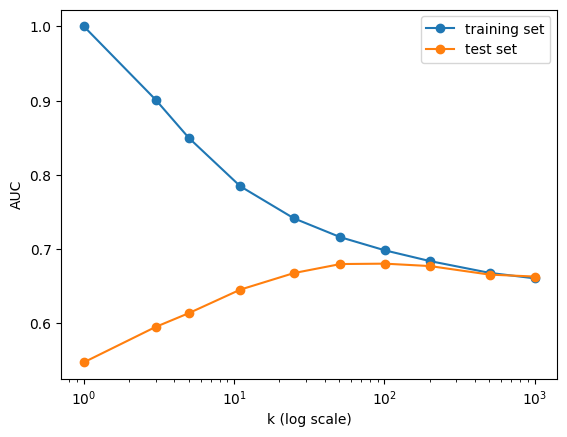

In [63]:
scaler_knn = StandardScaler().fit(X_train)
X_train_knn = scaler_knn.transform(X_train)[:20000]
y_train_knn = y_train.iloc[:20000]
X_test_knn = scaler_knn.transform(X_test)

k_values = [1, 3, 5, 11, 25, 51, 101, 201, 501, 1001]
train_auc = []
test_auc = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_knn)
    train_auc.append(metrics.roc_auc_score(y_train_knn, knn.predict_proba(X_train_knn)[:, 1]))
    test_auc.append(metrics.roc_auc_score(y_test, knn.predict_proba(X_test_knn)[:, 1]))
    print('k =', k, ' train AUC =', round(train_auc[-1], 3), ' test AUC =', round(test_auc[-1], 3))

plt.plot(k_values, train_auc, marker='o', label='training set')
plt.plot(k_values, test_auc, marker='o', label='test set')
plt.xscale('log')
plt.xlabel('k (log scale)')
plt.ylabel('AUC')
plt.legend()
plt.show()

With k = 1 the training AUC is 1 and the test AUC 0.55. The test AUC is best at k = 101 (0.68), close to the logistic regression and below the random forest.

## 5.5 Feature importance (4.3)

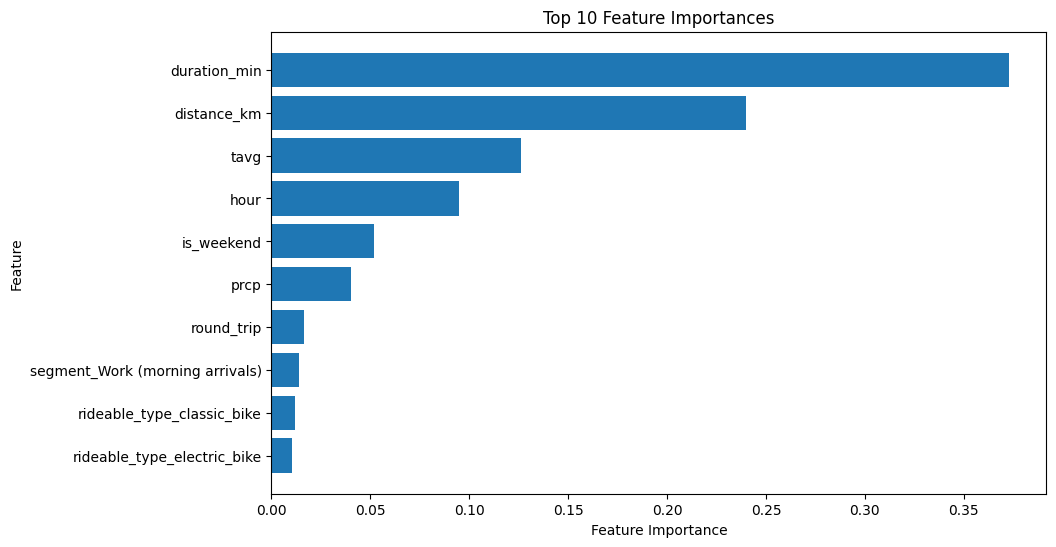

In [64]:
feature_names = X.columns
importances = rf_classifier.feature_importances_

N = 10
top_indices = np.argsort(importances)[::-1][:N]
top_feature_importances = importances[top_indices]
top_feature_names = [feature_names[i] for i in top_indices]

plt.figure(figsize=(10, 6))
plt.barh(range(len(top_feature_importances)), top_feature_importances, align='center')
plt.yticks(range(len(top_feature_importances)), top_feature_names)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title(f'Top {N} Feature Importances')
plt.gca().invert_yaxis()
plt.show()

In [65]:
# what if we do not know the duration of the ride (when the bike is unlocked)?
clf = LogisticRegression(max_iter=1000).fit(X_train, y_train)
print('all features AUC:', metrics.roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1]))
clf = LogisticRegression(max_iter=1000).fit(X_train.drop(columns=['duration_min']), y_train)
print('without duration AUC:', metrics.roc_auc_score(y_test, clf.predict_proba(X_test.drop(columns=['duration_min']))[:, 1]))

all features AUC: 0.6864349726709711


without duration AUC: 0.6240123886307958


Duration and distance are the most important variables. Without the duration the AUC of the logistic regression falls from 0.69 to 0.62.

## 5.6 Imbalance: SMOTE and over-sampling (4.4)

Resampling is done only on the training set, the test set keeps the real 18% of casual rides.

In [66]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

X_train_smote, y_train_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
X_train_over, y_train_over = RandomOverSampler(random_state=42).fit_resample(X_train, y_train)
X_train_under, y_train_under = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
print(y_train_smote.value_counts())

member_casual
0    131558
1    131558
Name: count, dtype: int64


In [67]:
pred = LogisticRegression(max_iter=1000).fit(X_train, y_train).predict(X_test)
print('original training set')
print(classification_report(y_test, pred))

pred = LogisticRegression(max_iter=1000).fit(X_train_smote, y_train_smote).predict(X_test)
print('SMOTE')
print(classification_report(y_test, pred))

pred = LogisticRegression(max_iter=1000).fit(X_train_over, y_train_over).predict(X_test)
print('random over-sampling')
print(classification_report(y_test, pred))

pred = LogisticRegression(max_iter=1000).fit(X_train_under, y_train_under).predict(X_test)
print('random under-sampling')
print(classification_report(y_test, pred))

original training set
              precision    recall  f1-score   support

           0       0.83      0.99      0.90     32894
           1       0.55      0.07      0.13      7142

    accuracy                           0.82     40036
   macro avg       0.69      0.53      0.52     40036
weighted avg       0.78      0.82      0.76     40036



SMOTE
              precision    recall  f1-score   support

           0       0.86      0.83      0.84     32894
           1       0.32      0.38      0.35      7142

    accuracy                           0.75     40036
   macro avg       0.59      0.60      0.60     40036
weighted avg       0.76      0.75      0.75     40036



random over-sampling
              precision    recall  f1-score   support

           0       0.88      0.72      0.79     32894
           1       0.30      0.55      0.39      7142

    accuracy                           0.69     40036
   macro avg       0.59      0.64      0.59     40036
weighted avg       0.78      0.69      0.72     40036



random under-sampling
              precision    recall  f1-score   support

           0       0.88      0.72      0.79     32894
           1       0.30      0.55      0.39      7142

    accuracy                           0.69     40036
   macro avg       0.59      0.64      0.59     40036
weighted avg       0.78      0.69      0.72     40036



The recall of casual riders goes from 7% to 38% with SMOTE and 55% with over-sampling, the precision falls from 55% to 32% and 30% and the F1 goes from 0.13 to 0.35 and 0.39. For a membership offer a false positive (a member who gets the offer) costs almost nothing, so we prefer the higher recall.

## 5.7 Casual riders who ride like members

In [68]:
test = trips.loc[X_test.index].copy()
test['proba_casual'] = rf_classifier.predict_proba(X_test)[:, 1]
look_like_members = test[(test['member_casual'] == 'casual') & (test['proba_casual'] < 0.5)]
recognised = test[(test['member_casual'] == 'casual') & (test['proba_casual'] >= 0.5)]
print('casual rides in the test set:', (test['member_casual'] == 'casual').sum())
print('classified as members:', len(look_like_members))
look_like_members[['duration_min', 'distance_km']].median()

casual rides in the test set: 7142
classified as members: 6552


duration_min    11.686308
distance_km      1.711393
dtype: float64

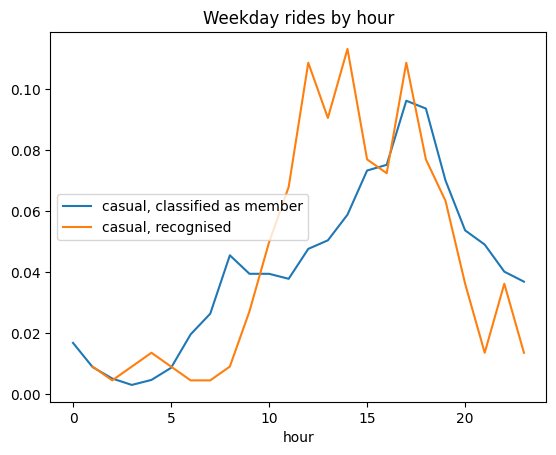

In [69]:
look_like_members[look_like_members['is_weekend'] == False]['hour'].value_counts(normalize=True).sort_index().plot(label='casual, classified as member')
recognised[recognised['is_weekend'] == False]['hour'].value_counts(normalize=True).sort_index().plot(label='casual, recognised')
plt.legend()
plt.title('Weekday rides by hour')
plt.show()

At the 0.5 threshold the forest labels 6,552 of the 7,142 casual rides as member rides. This is the imbalance and the overlap between the groups, it does not mean that 92% of casual riders are commuters. The 590 casual rides it recognises are more around midday. H2 is only partly true (best AUC 0.72), but the overlap is an opportunity: the casual riders who often ride on weekdays at commuting peaks (28% of casual rides) are the people to offer a membership to.

# 6. Will the station be empty tomorrow morning? (sessions 4.1 to 4.4)

Every evening the operator decides where the trucks go. With only what is known the evening before, we predict if a station will be empty for at least one hour of tomorrow's 7-10am (empty in at least 33% of the snapshots).

The variables: the state of the station today (share of the morning and of the evening empty or full), today's departures, arrivals and morning net flow, capacity and type, and tomorrow's calendar and weather (the observed weather stands in for the forecast).

In [70]:
tomorrow = station_day[['station_name', 'date', 'pct_empty_morning', 'weekday', 'is_weekend', 'holiday', 'tavg', 'prcp']].copy()
tomorrow['date'] = tomorrow['date'] - pd.Timedelta(days=1)
tomorrow.columns = ['station_name', 'date', 'tomorrow_pct_empty_morning', 'tomorrow_weekday', 'tomorrow_is_weekend', 'tomorrow_holiday', 'tomorrow_tavg', 'tomorrow_prcp']

data = station_day.merge(tomorrow, on=['station_name', 'date'])
data['empty_tomorrow'] = (data['tomorrow_pct_empty_morning'] >= 33).astype(int)
data['net_flow_morning'] = data['arr_morning'] - data['dep_morning']
data = data.dropna(subset=['tomorrow_tavg', 'tomorrow_prcp'])
data['empty_tomorrow'].value_counts(normalize=True)

empty_tomorrow
0    0.953281
1    0.046719
Name: proportion, dtype: float64

## 6.1 Why today predicts tomorrow

In [71]:
data['empty_today'] = pd.cut(data['pct_empty_morning'], bins=[-1, 0, 10, 33, 66, 100], labels=['never', '0-10%', '10-33%', '33-66%', '66-100%'])
data.groupby('empty_today', observed=True)['empty_tomorrow'].agg(['mean', 'size'])

,mean,size
empty_today,,
never,0.027170,738131
0-10%,0.082532,22246
10-33%,0.127904,29960
33-66%,0.256056,20558
66-100%,0.422884,18336


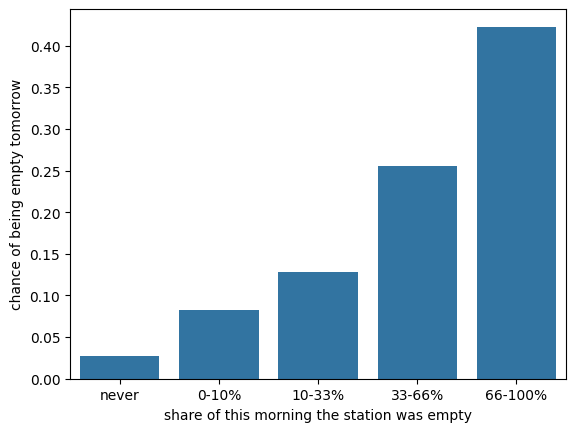

In [72]:
sns.barplot(data=data, x='empty_today', y='empty_tomorrow', errorbar=None)
plt.xlabel('share of this morning the station was empty')
plt.ylabel('chance of being empty tomorrow')
plt.show()

A station never empty this morning (89% of station-days) has a 2.7% chance of a shortage tomorrow, one empty more than two thirds of the morning has 42.3%. The problem is persistent.

## 6.2 Comparing models with cross-validation (4.1)

150,000 station-days, 80% to train and 20% to test. Cross-validation is done on the training set only. The ladder of 4.3: logistic regression, decision tree, random forest, XGBoost.

In [73]:
features_e = ['pct_empty_morning', 'pct_full_morning', 'pct_empty_evening', 'pct_full_evening', 'departures', 'arrivals', 'net_flow_morning',
              'capacity', 'segment', 'tomorrow_weekday', 'tomorrow_is_weekend', 'tomorrow_holiday', 'tomorrow_tavg', 'tomorrow_prcp']

sample_e = data.sample(150000, random_state=42)
X_e = pd.get_dummies(sample_e[features_e], columns=['segment'], dtype='int')
y_e = sample_e['empty_tomorrow']

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_e, y_e, test_size=0.2, random_state=42)
X_train_e.shape, X_test_e.shape

((120000, 17), (30000, 17))

In [74]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=10)

log_e = LogisticRegression(max_iter=1000)
s = cross_val_score(log_e, X_train_e, y_train_e, cv=cv5, scoring='roc_auc')
print('Logistic       CV AUC =', s.mean().round(4), '+/-', s.std().round(4))

tree_e = DecisionTreeClassifier(max_depth=5, random_state=42)
s = cross_val_score(tree_e, X_train_e, y_train_e, cv=cv5, scoring='roc_auc')
print('Tree (depth 5) CV AUC =', s.mean().round(4), '+/-', s.std().round(4))

rf_e = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=42)
s = cross_val_score(rf_e, X_train_e, y_train_e, cv=cv5, scoring='roc_auc')
print('Random forest  CV AUC =', s.mean().round(4), '+/-', s.std().round(4))

xgb_e = xgb.XGBClassifier(max_depth=4, learning_rate=0.3, n_estimators=100, random_state=42)
s = cross_val_score(xgb_e, X_train_e, y_train_e, cv=cv5, scoring='roc_auc')
print('XGBoost        CV AUC =', s.mean().round(4), '+/-', s.std().round(4))

Logistic       CV AUC = 0.8603 +/- 0.0038


Tree (depth 5) CV AUC = 0.842 +/- 0.0041


Random forest  CV AUC = 0.8909 +/- 0.0021


XGBoost        CV AUC = 0.8991 +/- 0.0031


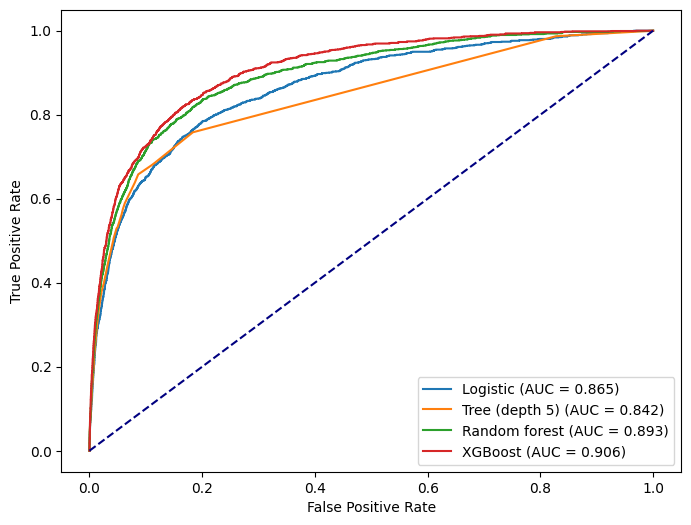

In [75]:
# the same four models on the test set
log_e.fit(X_train_e, y_train_e)
tree_e.fit(X_train_e, y_train_e)
rf_e.fit(X_train_e, y_train_e)
xgb_e.fit(X_train_e, y_train_e)

plt.figure(figsize=(8, 6))
for name, clf in [('Logistic', log_e), ('Tree (depth 5)', tree_e), ('Random forest', rf_e), ('XGBoost', xgb_e)]:
    fpr, tpr, thresholds = roc_curve(y_test_e, clf.predict_proba(X_test_e)[:, 1])
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

XGBoost (0.906 on the test set, 0.899 in CV) is ahead of the random forest (0.893), the logistic regression (0.865) and the tree (0.842). The standard deviations across folds are small, and the test AUC is close to the CV one, so no overfitting.

## 6.3 XGBoost as in session 4.3

In [76]:
dtrain = xgb.DMatrix(X_train_e, label=y_train_e)
dtest = xgb.DMatrix(X_test_e, label=y_test_e)

params = {
    "objective": "binary:logistic",
    "max_depth": 4,
    "eta": 0.3,
    "seed": 42
}
num_round = 100
xgb_model = xgb.train(params, dtrain, num_round)

y_proba_xgb = xgb_model.predict(dtest)
y_pred_xgb = (y_proba_xgb >= 0.5).astype(int)
print(classification_report(y_test_e, y_pred_xgb))

fpr, tpr, thresholds = roc_curve(y_test_e, y_proba_xgb)
print('AUC:', auc(fpr, tpr))

              precision    recall  f1-score   support

           0       0.96      0.99      0.98     28623
           1       0.63      0.24      0.35      1377

    accuracy                           0.96     30000
   macro avg       0.80      0.62      0.67     30000
weighted avg       0.95      0.96      0.95     30000

AUC: 0.9064238323609471


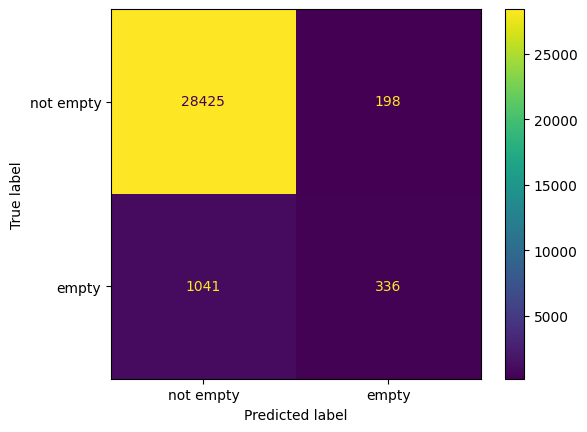

In [77]:
ConfusionMatrixDisplay(confusion_matrix(y_test_e, y_pred_xgb), display_labels=['not empty', 'empty']).plot()
plt.show()

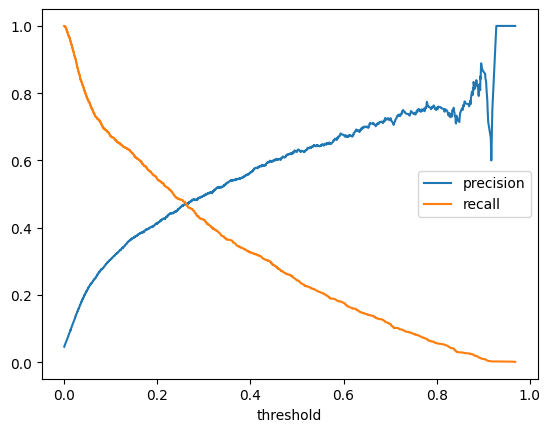

threshold of the top 10%: 0.10135085


In [78]:
precision, recall, thr = metrics.precision_recall_curve(y_test_e, y_proba_xgb)
plt.plot(thr, precision[:-1], label='precision')
plt.plot(thr, recall[:-1], label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

# probability of the last station in the top 10%
print('threshold of the top 10%:', np.sort(y_proba_xgb)[::-1][2999])

At 0.5 the model is careful: precision 63% but recall only 24% (336 of the 1,377 empty stations found). The trucks need a ranking, not a yes or no, so we use the list of the stations with the highest probability. The top 10% corresponds to a probability of about 0.10.

## 6.4 What drives the prediction

In [79]:
# importance = average gain of the splits on each variable, in % of the total
gain = pd.Series(xgb_model.get_score(importance_type='gain'))
(gain / gain.sum() * 100).sort_values(ascending=False).round(1)

pct_empty_evening                           30.3
pct_empty_morning                           17.5
arrivals                                     9.5
segment_Work (morning arrivals)              7.9
pct_full_morning                             7.2
tomorrow_weekday                             4.4
segment_Low demand / leisure                 3.9
pct_full_evening                             3.0
segment_Residential (morning departures)     2.9
segment_Busy mixed                           2.7
departures                                   2.6
tomorrow_holiday                             2.0
net_flow_morning                             1.8
capacity                                     1.7
tomorrow_tavg                                1.6
tomorrow_prcp                                1.1
dtype: float64

We also remove one group of variables at a time, retrain and look at how much the AUC drops (ablation).

In [80]:
groups = {'none (all features)': [],
          "today's state of the station": ['pct_empty_morning', 'pct_full_morning', 'pct_empty_evening', 'pct_full_evening'],
          "today's rides": ['departures', 'arrivals', 'net_flow_morning'],
          'weather': ['tomorrow_tavg', 'tomorrow_prcp'],
          'calendar': ['tomorrow_weekday', 'tomorrow_is_weekend', 'tomorrow_holiday'],
          'station (capacity + segment)': ['capacity'] + [c for c in X_e.columns if c.startswith('segment')]}

for name, drop in groups.items():
    m = xgb.XGBClassifier(max_depth=4, learning_rate=0.3, n_estimators=100, random_state=42)
    m.fit(X_train_e.drop(columns=drop), y_train_e)
    print('without', name, ' AUC =', round(metrics.roc_auc_score(y_test_e, m.predict_proba(X_test_e.drop(columns=drop))[:, 1]), 4))

without none (all features)  AUC = 0.9064


without today's state of the station  AUC = 0.7615


without today's rides  AUC = 0.8808


without weather  AUC = 0.9066


without calendar  AUC = 0.8916


without station (capacity + segment)  AUC = 0.8987


The empty share this evening and this morning are the most important variables. Without the state of the station today the AUC falls from 0.906 to 0.762; removing the weather leaves the AUC essentially unchanged. The weather matters for how many people ride in the city, not for where bikes run out.

## 6.5 Random forest with SMOTE (4.4)

In [81]:
print(classification_report(y_test_e, rf_e.predict(X_test_e)))

X_res, y_res = SMOTE(random_state=42).fit_resample(X_train_e, y_train_e)
rf_smote = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=42)
rf_smote.fit(X_res, y_res)
print(classification_report(y_test_e, rf_smote.predict(X_test_e)))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98     28623
           1       0.67      0.15      0.24      1377

    accuracy                           0.96     30000
   macro avg       0.82      0.57      0.61     30000
weighted avg       0.95      0.96      0.94     30000



              precision    recall  f1-score   support

           0       0.98      0.95      0.96     28623
           1       0.33      0.56      0.42      1377

    accuracy                           0.93     30000
   macro avg       0.66      0.75      0.69     30000
weighted avg       0.95      0.93      0.94     30000



With SMOTE the recall of empty stations goes from 15% to 56%, with more false alarms. A missed empty station is worse than a useless stop, so recall matters more. In practice we get the same effect by taking a list of the riskiest stations.

## 6.6 From probabilities to a list for the trucks

If the trucks visit the 5%, 10%, 20% or 30% of stations with the highest probability:

In [82]:
test_e = sample_e.loc[X_test_e.index].copy()
test_e['proba_empty'] = y_proba_xgb
ranked = test_e.sort_values('proba_empty', ascending=False)
print('share of station-days empty tomorrow:', test_e['empty_tomorrow'].mean())

for p in [5, 10, 20, 30]:
    top = ranked.head(int(len(ranked) * p / 100))
    print('top', p, '%  hit rate:', round(top['empty_tomorrow'].mean(), 3), '  empty stations caught:', round(top['empty_tomorrow'].sum() / test_e['empty_tomorrow'].sum(), 3))

share of station-days empty tomorrow: 0.0459
top 5 %  hit rate: 0.449   empty stations caught: 0.489
top 10 %  hit rate: 0.308   empty stations caught: 0.67
top 20 %  hit rate: 0.189   empty stations caught: 0.823
top 30 %  hit rate: 0.138   empty stations caught: 0.899


In [83]:
top10 = ranked.head(3000)
pd.DataFrame({'all station-days': test_e['segment'].value_counts(normalize=True), 'top 10% list': top10['segment'].value_counts(normalize=True)}).round(3)

,all station-days,top 10% list
segment,,
Busy mixed,0.362,0.206
Low demand / leisure,0.217,0.290
Residential (morning departures),0.273,0.444
Work (morning arrivals),0.148,0.060


The 10% list catches 67% of the stations that will be empty, and 31% of the listed stations really are empty (4.6% for a random list). Residential stations are 27% of station-days but 44% of the list.

## 6.7 Against a simple rule, night by night

A random list is too easy to beat. Without a model, an operator would visit the stations that were empty longest today. Here we split by date: 80% of the nights to train, 20% to test, and each night every method lists the same number of stations.

In [84]:
dates = pd.Series(data['date'].unique())
test_dates = dates.sample(frac=0.2, random_state=42)
is_test = data['date'].isin(test_dates)

X_night = pd.get_dummies(data[features_e], columns=['segment'], dtype='int')
night_model = xgb.XGBClassifier(max_depth=4, learning_rate=0.3, n_estimators=100, random_state=42)
night_model.fit(X_night[~is_test], data.loc[~is_test, 'empty_tomorrow'])

nights = data[is_test].copy()
nights['proba_empty'] = night_model.predict_proba(X_night[is_test])[:, 1]
print('test nights:', nights['date'].nunique())
print('AUC model:', metrics.roc_auc_score(nights['empty_tomorrow'], nights['proba_empty']))
print('AUC rule "empty longest today":', metrics.roc_auc_score(nights['empty_tomorrow'], nights['pct_empty_day']))

test nights: 77
AUC model: 0.9047077086709533
AUC rule "empty longest today": 0.8554021167685008


In [85]:
# each night, list the share of stations with the highest score
def nightly_list(score, share):
    caught, total, listed = 0, 0, 0
    per_night = []
    for date, night in nights.groupby('date'):
        k = int(round(len(night) * share))
        top = night.sort_values(score, ascending=False, kind='mergesort').head(k)
        caught += top['empty_tomorrow'].sum()
        total += night['empty_tomorrow'].sum()
        listed += k
        per_night.append(top['empty_tomorrow'].sum() / night['empty_tomorrow'].sum())
    return caught / total, caught / listed, per_night

for share in [0.05, 0.10, 0.20]:
    print('list of', share)
    print('  model:                    caught %.3f  hit rate %.3f' % nightly_list('proba_empty', share)[:2])
    print('  rule empty longest today: caught %.3f  hit rate %.3f' % nightly_list('pct_empty_day', share)[:2])
    print('  rule empty this evening:  caught %.3f  hit rate %.3f' % nightly_list('pct_empty_evening', share)[:2])

list of 0.05
  model:                    caught 0.425  hit rate 0.419
  rule empty longest today: caught 0.326  hit rate 0.322
  rule empty this evening:  caught 0.314  hit rate 0.310
list of 0.1


  model:                    caught 0.621  hit rate 0.306


  rule empty longest today: caught 0.515  hit rate 0.254
  rule empty this evening:  caught 0.478  hit rate 0.236
list of 0.2
  model:                    caught 0.794  hit rate 0.196
  rule empty longest today: caught 0.755  hit rate 0.186


  rule empty this evening:  caught 0.632  hit rate 0.156


nights where the model catches more than the rule: 68 of 77


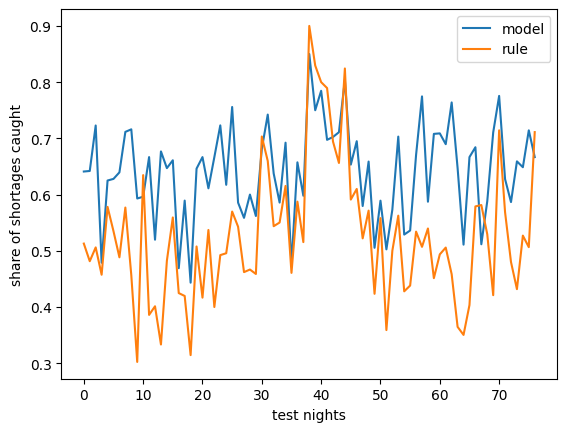

In [86]:
model_nights = nightly_list('proba_empty', 0.10)[2]
rule_nights = nightly_list('pct_empty_day', 0.10)[2]
print('nights where the model catches more than the rule:', sum(np.array(model_nights) > np.array(rule_nights)), 'of', len(model_nights))

plt.plot(model_nights, label='model')
plt.plot(rule_nights, label='rule')
plt.ylabel('share of shortages caught')
plt.xlabel('test nights')
plt.legend()
plt.show()

With 10% of the stations the model catches 62% of the next morning's shortages, the rule 51% and a random list 10%. The model is better on 68 of the 77 test nights.

## 6.8 Where to take the bikes from

At night work stations are mostly empty, so the spare bikes are not there. We take them from stations full this evening (at least a third of 4-8pm) that the model ranks at low risk (the half with the lowest probability).

In [87]:
full_tomorrow = station_day[['station_name', 'date', 'pct_full_morning']].copy()
full_tomorrow['date'] = full_tomorrow['date'] - pd.Timedelta(days=1)
full_tomorrow.columns = ['station_name', 'date', 'tomorrow_pct_full_morning']
nights = nights.merge(full_tomorrow, on=['station_name', 'date'], how='left')
nights['full_tomorrow'] = (nights['tomorrow_pct_full_morning'] >= 33).astype(int)

dropoff = nights.groupby('date', group_keys=False).apply(lambda n: n.nlargest(int(round(len(n) * 0.10)), 'proba_empty'))
full_tonight = nights[nights['pct_full_evening'] >= 33]
pickup = full_tonight[full_tonight['proba_empty'] <= full_tonight['proba_empty'].median()]

n_nights = nights['date'].nunique()
print('drop-off list: %.1f stations a night, %.1f%% empty and %.1f%% full the next morning' % (len(dropoff) / n_nights, dropoff['empty_tomorrow'].mean() * 100, dropoff['full_tomorrow'].mean() * 100))
print('full this evening: %.1f stations a night, %.1f%% empty and %.1f%% full' % (len(full_tonight) / n_nights, full_tonight['empty_tomorrow'].mean() * 100, full_tonight['full_tomorrow'].mean() * 100))
print('pick-up list: %.1f stations a night, %.1f%% empty and %.1f%% full' % (len(pickup) / n_nights, pickup['empty_tomorrow'].mean() * 100, pickup['full_tomorrow'].mean() * 100))
print('all stations: %.1f stations a night, %.1f%% empty and %.1f%% full' % (len(nights) / n_nights, nights['empty_tomorrow'].mean() * 100, nights['full_tomorrow'].mean() * 100))

drop-off list: 214.8 stations a night, 30.6% empty and 0.7% full the next morning
full this evening: 134.5 stations a night, 1.0% empty and 38.9% full
pick-up list: 67.3 stations a night, 0.1% empty and 52.5% full
all stations: 2148.0 stations a night, 4.9% empty and 6.8% full


In [88]:
pd.DataFrame({'drop-off': dropoff['segment'].value_counts(normalize=True), 'pick-up': pickup['segment'].value_counts(normalize=True),
              'all stations': nights['segment'].value_counts(normalize=True)}).round(3)

,drop-off,pick-up,all stations
segment,,,
Busy mixed,0.183,0.393,0.363
Low demand / leisure,0.332,0.312,0.214
Residential (morning departures),0.425,0.177,0.277
Work (morning arrivals),0.060,0.118,0.146


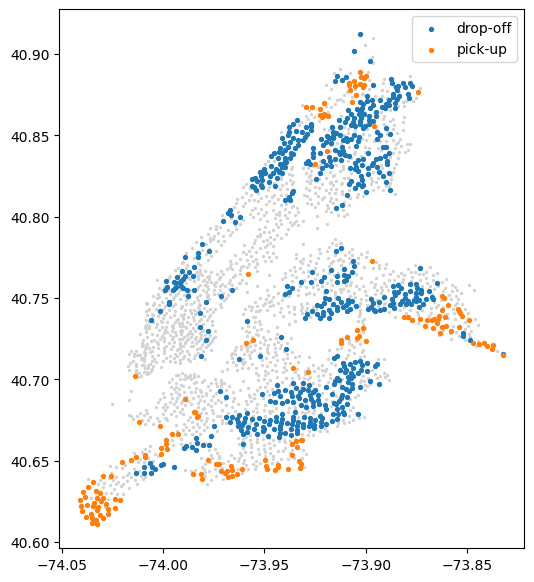

In [89]:
# stations on the lists on at least 15% of the test nights
on_drop = nights.index.isin(dropoff.index)
on_pick = nights.index.isin(pickup.index)
freq = nights.assign(drop=on_drop, pick=on_pick).groupby('station_name')[['drop', 'pick']].mean()
freq = freq.join(stations.set_index('station_name')[['lat', 'lng']])

plt.figure(figsize=(6, 7))
plt.scatter(freq['lng'], freq['lat'], s=2, color='lightgrey')
plt.scatter(freq[freq['drop'] > 0.15]['lng'], freq[freq['drop'] > 0.15]['lat'], s=8, label='drop-off')
plt.scatter(freq[freq['pick'] > 0.15]['lng'], freq[freq['pick'] > 0.15]['lat'], s=8, label='pick-up')
plt.legend()
plt.show()

On the pick-up list only 0.1% of the stations are empty the next morning and 52.5% are full again, so collecting there is safe and also frees docks (the driver still checks the live number of bikes and leaves a reserve). These are mostly busy mixed and low-demand stations. The drop-off list is mostly residential stations, then low-demand ones.

# 7. Robustness

## 7.1 Stress test: train in one season, test on the following months (H5)

Both the XGBoost model and the demand regression are trained on August to October 2025 only and tested month by month. (`month` is not in the regression here, because the training period has only three months.)

In [90]:
X_all = pd.get_dummies(data[features_e], columns=['segment'], dtype='int')
y_all = data['empty_tomorrow']
train_mask = (data['date'] >= '2025-08-01') & (data['date'] < '2025-11-01')
stress_model = xgb.XGBClassifier(max_depth=4, learning_rate=0.3, n_estimators=100, random_state=42)
stress_model.fit(X_all[train_mask], y_all[train_mask])

reg_all = station_day.dropna(subset=['departures_last_week', 'tavg', 'prcp']).copy()
reg_all['log_departures'] = np.log1p(reg_all['departures'])
reg_all['log_departures_last_week'] = np.log1p(reg_all['departures_last_week'])
X_reg_all = pd.get_dummies(reg_all[['weekday', 'holiday', 'tavg', 'prcp', 'wspd', 'capacity', 'segment', 'log_departures_last_week']],
                           columns=['weekday', 'segment'], drop_first=True, dtype='int')
y_reg_all = reg_all['log_departures']
reg_train = (reg_all['date'] >= '2025-08-01') & (reg_all['date'] < '2025-11-01')
stress_reg = LinearRegression().fit(X_reg_all[reg_train], y_reg_all[reg_train])

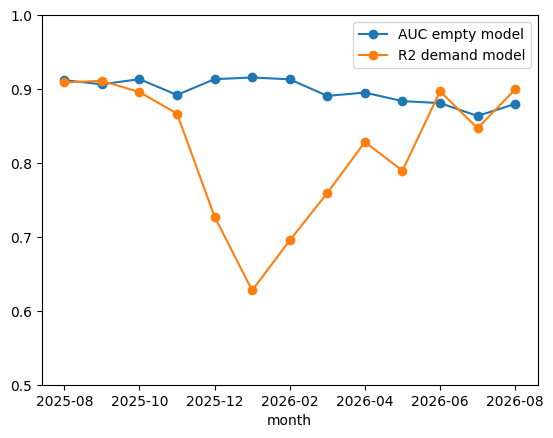

,AUC empty model,R2 demand model
month,,
2025-08,0.912,0.909
2025-09,0.906,0.911
2025-10,0.913,0.896
2025-11,0.892,0.867
2025-12,0.913,0.727
2026-01,0.916,0.628
2026-02,0.913,0.695
2026-03,0.891,0.759
2026-04,0.895,0.828


In [91]:
monthly = []
for month in pd.period_range('2025-08', '2026-08', freq='M'):
    m1 = data['date'].dt.to_period('M') == month
    m2 = reg_all['date'].dt.to_period('M') == month
    auc_month = metrics.roc_auc_score(y_all[m1], stress_model.predict_proba(X_all[m1])[:, 1])
    r2_month = stress_reg.score(X_reg_all[m2], y_reg_all[m2])
    monthly.append([str(month), auc_month, r2_month])
monthly = pd.DataFrame(monthly, columns=['month', 'AUC empty model', 'R2 demand model']).set_index('month')

monthly.plot(marker='o')
plt.ylim(0.5, 1)
plt.show()
monthly.round(3)

In [92]:
# the same by season
winter = (data['date'] >= '2025-12-01') & (data['date'] < '2026-03-01')
summer = (data['date'] >= '2026-06-01') & (data['date'] < '2026-09-01')
print('empty model, training months:', metrics.roc_auc_score(y_all[train_mask], stress_model.predict_proba(X_all[train_mask])[:, 1]))
print('empty model, winter:', metrics.roc_auc_score(y_all[winter], stress_model.predict_proba(X_all[winter])[:, 1]))
print('empty model, next summer:', metrics.roc_auc_score(y_all[summer], stress_model.predict_proba(X_all[summer])[:, 1]))

winter_reg = (reg_all['date'] >= '2025-12-01') & (reg_all['date'] < '2026-03-01')
summer_reg = (reg_all['date'] >= '2026-06-01') & (reg_all['date'] < '2026-09-01')
print('demand model, training months:', stress_reg.score(X_reg_all[reg_train], y_reg_all[reg_train]))
print('demand model, winter:', stress_reg.score(X_reg_all[winter_reg], y_reg_all[winter_reg]))
print('demand model, next summer:', stress_reg.score(X_reg_all[summer_reg], y_reg_all[summer_reg]))

empty model, training months: 0.9109123604063785
empty model, winter: 0.914039945401478
empty model, next summer: 0.8767846475831743
demand model, training months: 0.9051792973134788
demand model, winter: 0.6862069626286813
demand model, next summer: 0.881084370677087


The demand regression falls from R squared 0.905 to 0.686 in winter (0.63 in January) and comes back in summer: H5 holds for demand. The empty-station model stays between 0.86 and 0.92 every month (0.914 in winter), it drops a little one year later (0.877), so it should be retrained from time to time.

## 7.2 Does the result depend on the random split?

In [93]:
for seed in [0, 1, 2, 3, 4]:
    Xa, Xb, ya, yb = train_test_split(X_e, y_e, test_size=0.2, random_state=seed)
    m = xgb.XGBClassifier(max_depth=4, learning_rate=0.3, n_estimators=100, random_state=seed).fit(Xa, ya)
    print('random_state =', seed, ' AUC =', round(metrics.roc_auc_score(yb, m.predict_proba(Xb)[:, 1]), 4))

random_state = 0  AUC = 0.8982


random_state = 1  AUC = 0.9009


random_state = 2  AUC = 0.8959


random_state = 3  AUC = 0.9028


random_state = 4  AUC = 0.8968


Between 0.896 and 0.903: it does not depend on the split.

# 8. Conclusions

H1 (time explains a station's demand better than the station): not at station level, calendar 12% against 44% for the station and 83% with last week's rides; for the whole city the weather explains 78% of the daily rides.
H2 (the trip separates members and casual riders): partly, best AUC 0.72.
H3 (stations fall into a few types): yes, four types with opposite daily cycles, even if the silhouette is low.
H4 (weather is a secondary but real driver): partly, it drives the volume of the city but not where stations run empty.
H5 (models lose accuracy in another season): for the demand model, not for the empty-station model.

For Citi Bike: run the model every evening and rank the stations, refill residential stations first with bikes taken from stations that are full tonight and at low risk, fix the stations that are empty almost every day with more docks or bikes instead of a daily truck, use the weather forecast to plan how many trucks are needed, and offer a membership to the casual riders who ride at commuting peaks.